In [1]:
# !pip install scikit-learn-extra

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer
from sklearn_extra.cluster import KMedoids
from sklearn import cluster
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split, StratifiedKFold   
from scipy.cluster.hierarchy import dendrogram, linkage 
 

In [3]:
#pip install scikit-learn-extra

In [4]:
c_seg = pd.read_csv("customer_segmentation.csv")
c_seg.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
c_seg.shape

(2240, 29)

In [6]:
c_seg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [7]:
c_seg.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


### Exploratory Data Analysis / Feature engineering

**Label: Response -- to be dropped**

In [8]:
c_seg['Response'].unique() #.describe()


array([1, 0])

**Constant values across customers. no variance**

In [9]:
print(c_seg['Z_CostContact'].var()) 
print(c_seg['Z_Revenue'].var())

0.0
0.0


**Remove duplicates**

In [10]:
#Checking for duplicates 
dup = c_seg.duplicated()
# print("Duplicate Rows (except first occurrence):")
print(c_seg[dup])
# print(dup)

Empty DataFrame
Columns: [ID, Year_Birth, Education, Marital_Status, Income, Kidhome, Teenhome, Dt_Customer, Recency, MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, MntGoldProds, NumDealsPurchases, NumWebPurchases, NumCatalogPurchases, NumStorePurchases, NumWebVisitsMonth, AcceptedCmp3, AcceptedCmp4, AcceptedCmp5, AcceptedCmp1, AcceptedCmp2, Complain, Z_CostContact, Z_Revenue, Response]
Index: []

[0 rows x 29 columns]


**Check for null values**

In [11]:
#checking for missing values
c_seg.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [12]:
#Dropping the missing values in the Income column
c_seg = c_seg.dropna(subset=['Income']) # all rows with na ...

In [13]:
c_seg.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

**get the response data**

In [14]:
df_response = c_seg['Response']
df_response.shape

(2216,)

**Transform: Year >> Age, First date >> Longevity**

In [15]:
# print(type(datetime.now().strftime('%m-%d-%Y')))
# print(type(c_seg['Dt_Customer'][0]))

In [16]:
#Calculating the age of the customers
current_year = datetime.now().year
c_seg['Age'] = current_year - c_seg['Year_Birth']
c_seg.head()

# #Calculating the longevity/tenure of the customers 
# curr_date = datetime.now().strftime('%m-%d-%Y') #datetime.now()
# c_seg['Longevity'] = curr_date - c_seg['Dt_Customer']
# c_seg.head()

del_trans_cols = ['Year_Birth', 'Dt_Customer']
curr_date = pd.Timestamp(datetime.now().date()) # datetime.now().date().strftime('%Y-%m-%d') # pd.to_datetime(datetime.now(), format='%d-%m-%Y').date()   
# c_seg['Dt_Customer1'] = pd.to_datetime(c_seg['Dt_Customer']) 
c_seg['Dt_Customer'] = pd.to_datetime(c_seg['Dt_Customer'], format='%d-%m-%Y') 
c_seg['Longevity_Days'] = (curr_date - c_seg['Dt_Customer']).dt.days
c_seg.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Longevity_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,3,11,1,67,4249
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,3,11,0,70,3699
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,3,11,0,59,3898
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,3,11,0,40,3725
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,3,11,0,43,3747


In [17]:
# Droping the the irrelevant columns
irrel_cols = ['Response', 'ID', 'Z_CostContact', 'Z_Revenue']
drop_cols = irrel_cols + del_trans_cols
drop_cols
c_seg.drop(drop_cols, axis=1, inplace=True)
c_seg.head()

,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Age,Longevity_Days
0,Graduation,Single,58138.0,0,0,58,635,88,546,172,...,4,7,0,0,0,0,0,0,67,4249
1,Graduation,Single,46344.0,1,1,38,11,1,6,2,...,2,5,0,0,0,0,0,0,70,3699
2,Graduation,Together,71613.0,0,0,26,426,49,127,111,...,10,4,0,0,0,0,0,0,59,3898
3,Graduation,Together,26646.0,1,0,26,11,4,20,10,...,4,6,0,0,0,0,0,0,40,3725
4,PhD,Married,58293.0,1,0,94,173,43,118,46,...,6,5,0,0,0,0,0,0,43,3747


**Categorical variables**

In [18]:
#Extracting the categorical predictors
cat_pred_list = ['Education', 'Marital_Status','AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain']

df_categorical = c_seg[cat_pred_list]
df_categorical.head()

,Education,Marital_Status,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain
0,Graduation,Single,0,0,0,0,0,0
1,Graduation,Single,0,0,0,0,0,0
2,Graduation,Together,0,0,0,0,0,0
3,Graduation,Together,0,0,0,0,0,0
4,PhD,Married,0,0,0,0,0,0


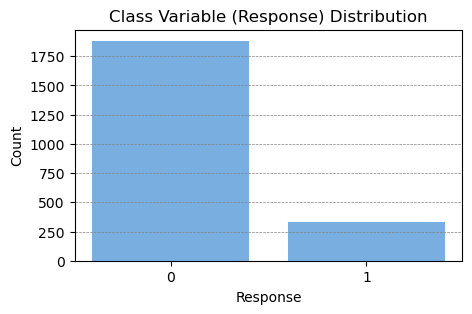

In [19]:

bar_color = '#79afe0'
df_response_counts = df_response.value_counts().sort_index()

# Plotting the bar chart
plt.figure(figsize=(5, 3))
plt.bar(df_response_counts.index.astype(str), df_response_counts.values, color=bar_color)

# Adding grid lines with a dotted style
plt.grid(axis='y', linestyle='--', linewidth=0.5, color='gray')

# Adding labels and title
plt.xlabel('Response')
plt.ylabel('Count')
plt.title('Class Variable (Response) Distribution')


# Show the plot
plt.show() 

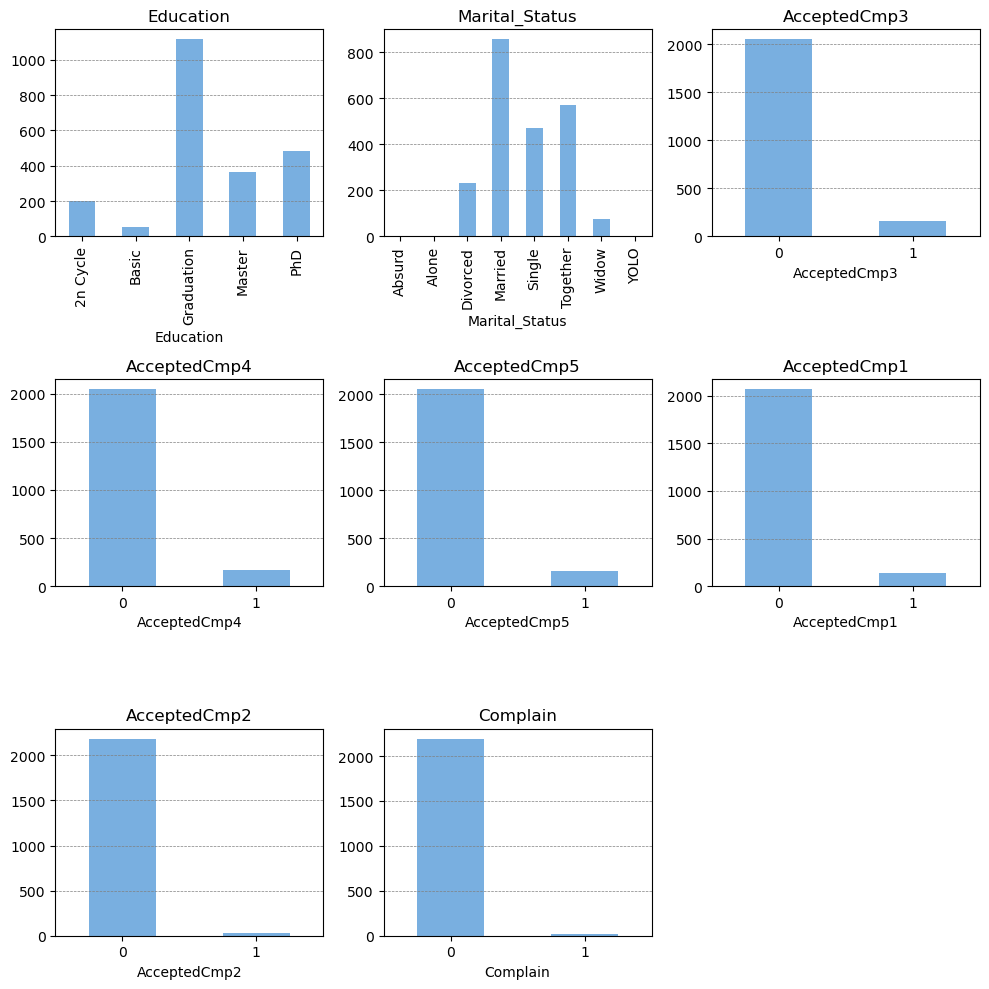

In [20]:

# Bar color from the uploaded image
bar_color = '#79afe0' # '#a1c7e9' # '#cbe0f3' # 

plt.figure(figsize=(10, 10))
n_categories = len(df_categorical.columns)
rows = (n_categories + 2) // 3  # Adjust rows as needed, +2 for rounding up in integer division

for i, column in enumerate(df_categorical.columns, start=1):
    ax = plt.subplot(rows, 3, i)  # Adjust the subplot layout as needed
    # Sort the counts for consistent ordering
    sorted_counts = df_categorical[column].value_counts().sort_index()
    sorted_counts.plot(kind='bar', ax=ax, color=bar_color)

    if i > 2:
        # Rotate x-axis labels
        ax.set_xticklabels(sorted_counts.index, rotation=0)
    
    plt.title(column)
    # Add grid lines with a dotted style
    ax.grid(axis='y', linestyle='--', linewidth=0.5, color='gray')

    
plt.tight_layout()
plt.show()


In [21]:
# #Barplot for categorical predictors 
# plt.figure(figsize=(18, 12))
# n_categories = len(df_categorical.columns)
# rows = (n_categories + 2) // 3  # Adjust rows as needed, +2 for rounding up in integer division

# for i, column in enumerate(df_categorical.columns, start=1):
#     ax = plt.subplot(rows, 3, i)  # Adjust the subplot layout as needed
#     sorted_counts = df_categorical[column].value_counts().sort_values(ascending=True)
#     sorted_counts.plot(kind='barh', ax=ax, color=['blue', 'green', 'purple', 'yellow', 'grey'])
#     plt.title(column)

# plt.tight_layout()
# plt.show()

**Continuous variables variables**

In [22]:
cont_list = list(set(c_seg.columns) - set(cat_pred_list) - set(irrel_cols))
cont_list

['NumCatalogPurchases',
 'MntFruits',
 'Teenhome',
 'MntWines',
 'MntSweetProducts',
 'Recency',
 'Income',
 'Age',
 'NumWebPurchases',
 'NumDealsPurchases',
 'MntGoldProds',
 'NumStorePurchases',
 'Kidhome',
 'Longevity_Days',
 'MntMeatProducts',
 'MntFishProducts',
 'NumWebVisitsMonth']

In [23]:
#Continuous Predictors
# df_continuous = new_df.drop(['Education', 'Marital_Status','AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain'], axis=1)

df_continuous = c_seg[cont_list] #.drop(cat_pred_list, axis=1)
df_continuous.head()

,NumCatalogPurchases,MntFruits,Teenhome,MntWines,MntSweetProducts,Recency,Income,Age,NumWebPurchases,NumDealsPurchases,MntGoldProds,NumStorePurchases,Kidhome,Longevity_Days,MntMeatProducts,MntFishProducts,NumWebVisitsMonth
0,10,88,0,635,88,58,58138.0,67,8,3,88,4,0,4249,546,172,7
1,1,1,1,11,1,38,46344.0,70,1,2,6,2,1,3699,6,2,5
2,2,49,0,426,21,26,71613.0,59,8,1,42,10,0,3898,127,111,4
3,0,4,0,11,3,26,26646.0,40,2,2,5,4,1,3725,20,10,6
4,3,43,0,173,27,94,58293.0,43,5,5,15,6,1,3747,118,46,5


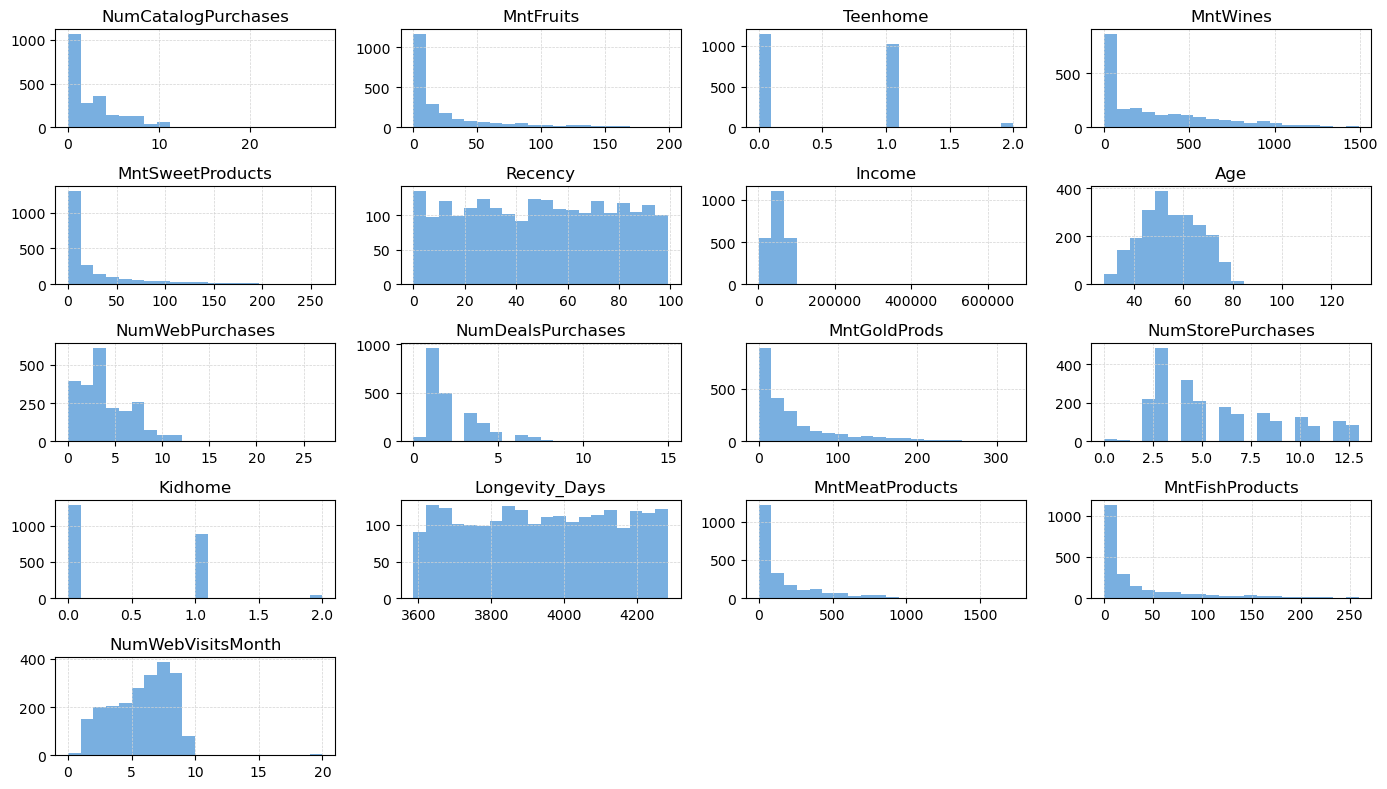

In [24]:

hist_color = '#79afe0' #'#a1c7e9' # '#79afe0' # 

# Plotting the histograms
axes = df_continuous.hist(figsize=(14, 8), bins=20, layout=(5, 4), color=hist_color)

# Customizing each subplot in the figure
for ax in axes.flatten():
    if ax is not None:
        ax.grid(True, linestyle='--', linewidth=0.5, color='lightgrey')  # Adding grid with specified color

plt.tight_layout()
plt.show()

In [25]:
# df_continuous['Teenhome'].unique()

In [26]:
cont_pred_list1 = ['Kidhome', 'Teenhome' ] 
cont_pred_list2 = ['Age','Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
cont_pred_list3 = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']
cont_pred_list4 = ['Longevity_Days']
cont_pred_list5 = ['Income']

df_continuous1 = df_continuous[cont_pred_list1]
df_continuous2 = df_continuous[cont_pred_list2]
df_continuous3 = df_continuous[cont_pred_list3]
df_continuous4 = df_continuous[cont_pred_list4]
df_continuous5 = df_continuous[cont_pred_list5]
# df_continuous3.head()

In [27]:
# #Checking for outliers using boxplots on continuous predictors
# plt.figure(figsize=(15, 8))  # Set the figure size
# sns.boxplot(data=df_continuous4)
# plt.title('Boxplot for Continuous Predictors')  # Title for the boxplot
# plt.ylabel('Values')  # Y-axis label
# plt.xlabel('Features')  # X-axis label
# plt.show() 

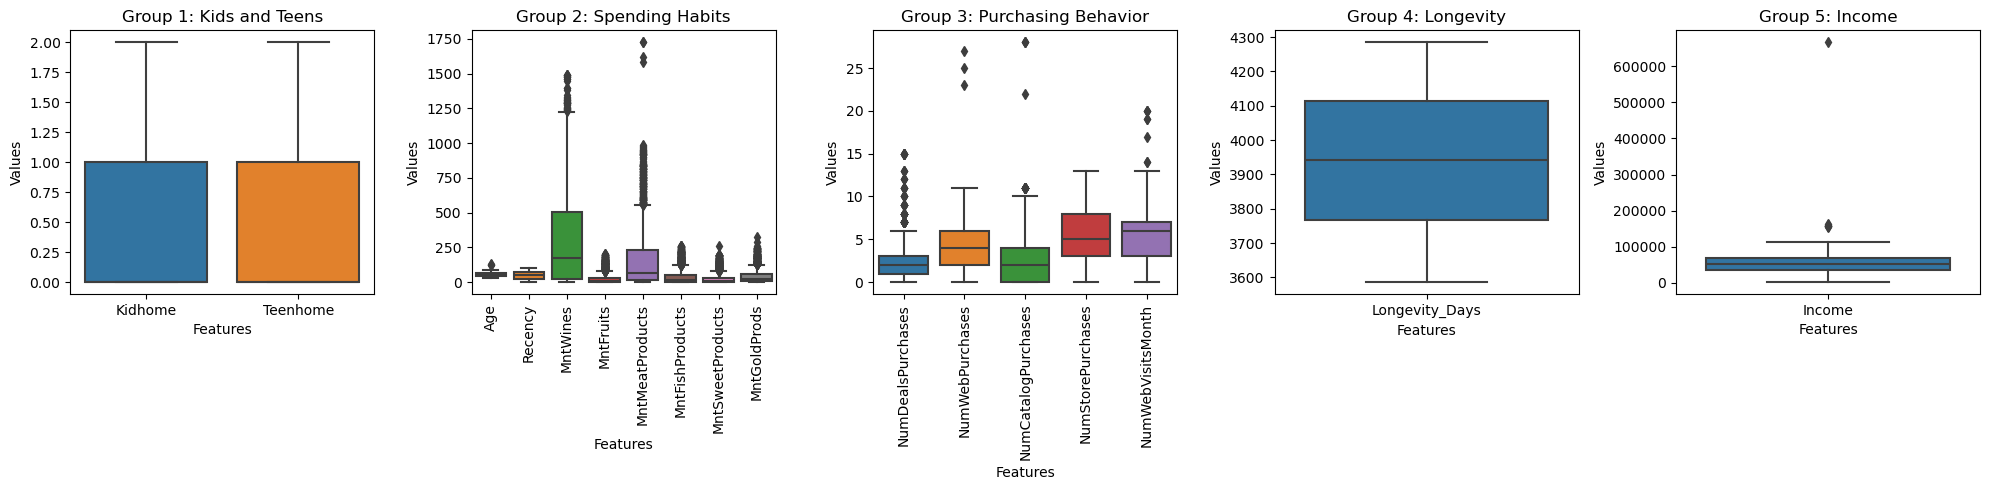

In [28]:

# Creating separate DataFrames for each group
dfs = [
    df_continuous[cont_pred_list1],
    df_continuous[cont_pred_list2],
    df_continuous[cont_pred_list3],
    df_continuous[cont_pred_list4],
    df_continuous[cont_pred_list5]
]
 
# Group lists and their labels for titles
groups = [
    ('Group 1: Kids and Teens', ['Kidhome', 'Teenhome']),
    ('Group 2: Spending Habits', ['Age', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']),
    ('Group 3: Purchasing Behavior', ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']),
    ('Group 4: Longevity', ['Longevity_Days']),
    ('Group 5: Income', ['Income'])
]

# Plotting
fig, axes = plt.subplots(1, 5, figsize=(20, 5))  # One subplot per group 
for ax, (title, features) in zip(axes, groups):
    sns.boxplot(data=df_continuous[features], ax=ax)
    rotate_num = 90 if len(features) > 3 else 0
    ax.set_xticklabels(ax.get_xticklabels(), rotation=rotate_num)  # Rotate x labels for better visibility
    ax.set_title(title)  # Use pre-defined titles
    ax.set_xlabel('Features')
    ax.set_ylabel('Values')

plt.tight_layout()
plt.show()

In [29]:
# groups = [
#     ('Group 1: Kids and Teens', ['Kidhome', 'Teenhome']),
#     ('Group 2: Spending Habits', ['Age', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']),
#     ('Group 3: Purchasing Behavior', ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']),
#     ('Group 4: Longevity', ['Longevity_Days']),
#     ('Group 5: Income', ['Income'])
# ]

# # Creating separate DataFrames for each group if not already done
# # df_continuous should be your continuous DataFrame containing all the features
# dfs = [df_continuous[list_features] for _, list_features in groups]

# # Plotting
# fig, axes = plt.subplots(3, 2, figsize=(15, 15))  # Adjust for 3 rows and 2 columns
# fig.suptitle('Boxplot Analysis for Continuous Predictors')

# for ax, (title, features), df in zip(axes.flatten(), groups, dfs):
#     sns.boxplot(data=df, ax=ax)
#     rotate_num = 90 if len(features) > 3 else 0  # Rotate labels if more than 3 features
#     ax.set_xticklabels(ax.get_xticklabels(), rotation=rotate_num)
#     ax.set_title(title)
#     ax.set_xlabel('Features')
#     ax.set_ylabel('Values')

# # Adjusting the last subplot if it's empty
# if len(groups) % 2 != 0:  # If groups are odd
#     fig.delaxes(axes.flatten()[-1])  # Remove the last subplot if unnecessary

# plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust the layout to make room for the global title
# plt.show()

In [30]:
# df_continuous2 = df_continuous[]
# df_continuous2.head()

In [31]:
# #Checking for outliers using boxplots on continuous predictors
# plt.figure(figsize=(15, 8))  # Set the figure size
# sns.boxplot(data=df_continuous2)
# plt.title('Boxplot for Continuous Predictors')  # Title for the boxplot
# plt.ylabel('Values')  # Y-axis label
# plt.xlabel('Features')  # X-axis label
# plt.show() 

**Collinearity between univariate predictors: remove high corr**

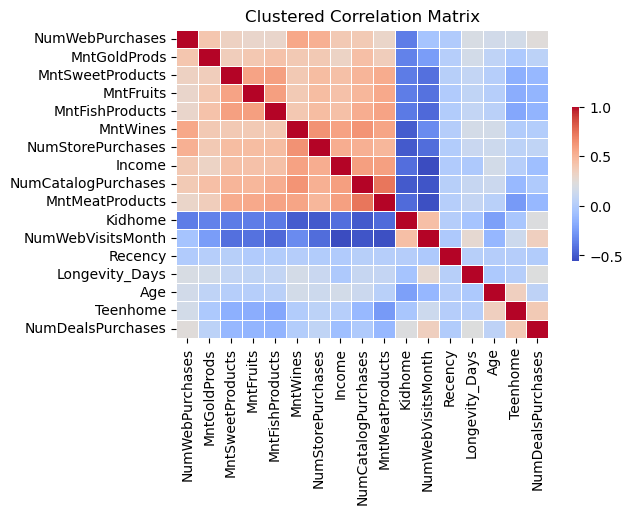

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage

# Calculate the correlation matrix
corr_matrix = df_continuous.corr()

# Compute the linkage matrix using Ward's method
link = linkage(corr_matrix, method='ward')

# Reorder the correlation matrix based on the linkage
dendro = dendrogram(link, labels=corr_matrix.columns, no_plot=True)
order = dendro['leaves']
corr_ordered = corr_matrix.iloc[order, :].iloc[:, order]

# Create the heatmap with the reordered correlation matrix
plt.figure(figsize=(6, 4))
sns.heatmap(corr_ordered, annot=False, cmap='coolwarm', fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .5})
plt.title('Clustered Correlation Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()


### Data Transformation

In [33]:
# #Correlation Matrix to check for highly correlated continuous predictors
# corr_matrix = df_continuous.corr()

# plt.figure(figsize=(8, 6)) 
# sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f") 
# # sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', annot=True, fmt=".2f",
# #             linewidths=.5, cbar_kws={"shrink": .5}, annot_kws={"size": 10})

# plt.title('Correlation Matrix')  
# plt.show()



# import matplotlib.pyplot as plt
# import seaborn as sns
# import numpy as np
# import pandas as pd

# # Calculate the correlation matrix
# corr_matrix = df_continuous.corr()

# # Create a mask for the upper triangle
# mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# # Initialize the matplotlib figure
# plt.figure(figsize=(8, 6))

# # Draw the heatmap
# # Ensure annot=True to display the correlation coefficients
# sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
# plt.title('Correlation Matrix')

# # Show the plot
# plt.show()

**Remove Skewness: Use BoxCox**

In [34]:
# Copy the DataFrame to keep the original data intact
df_transformed = df_continuous.copy()

for column in df_transformed.columns:
    # Add 1 to all values to handle non-positive values for Box-Cox transformation
    # This is a simple approach; you might need a more sophisticated method for your data
    adjusted_values = df_transformed[column] + 1
    
    # Try Box-Cox transformation
    try:
        transformed_data, _ = stats.boxcox(adjusted_values)
        df_transformed[column] = transformed_data
    except ValueError:
        # If Box-Cox fails, use the square root transformation as a fallback
        df_transformed[column] = np.sqrt(adjusted_values)

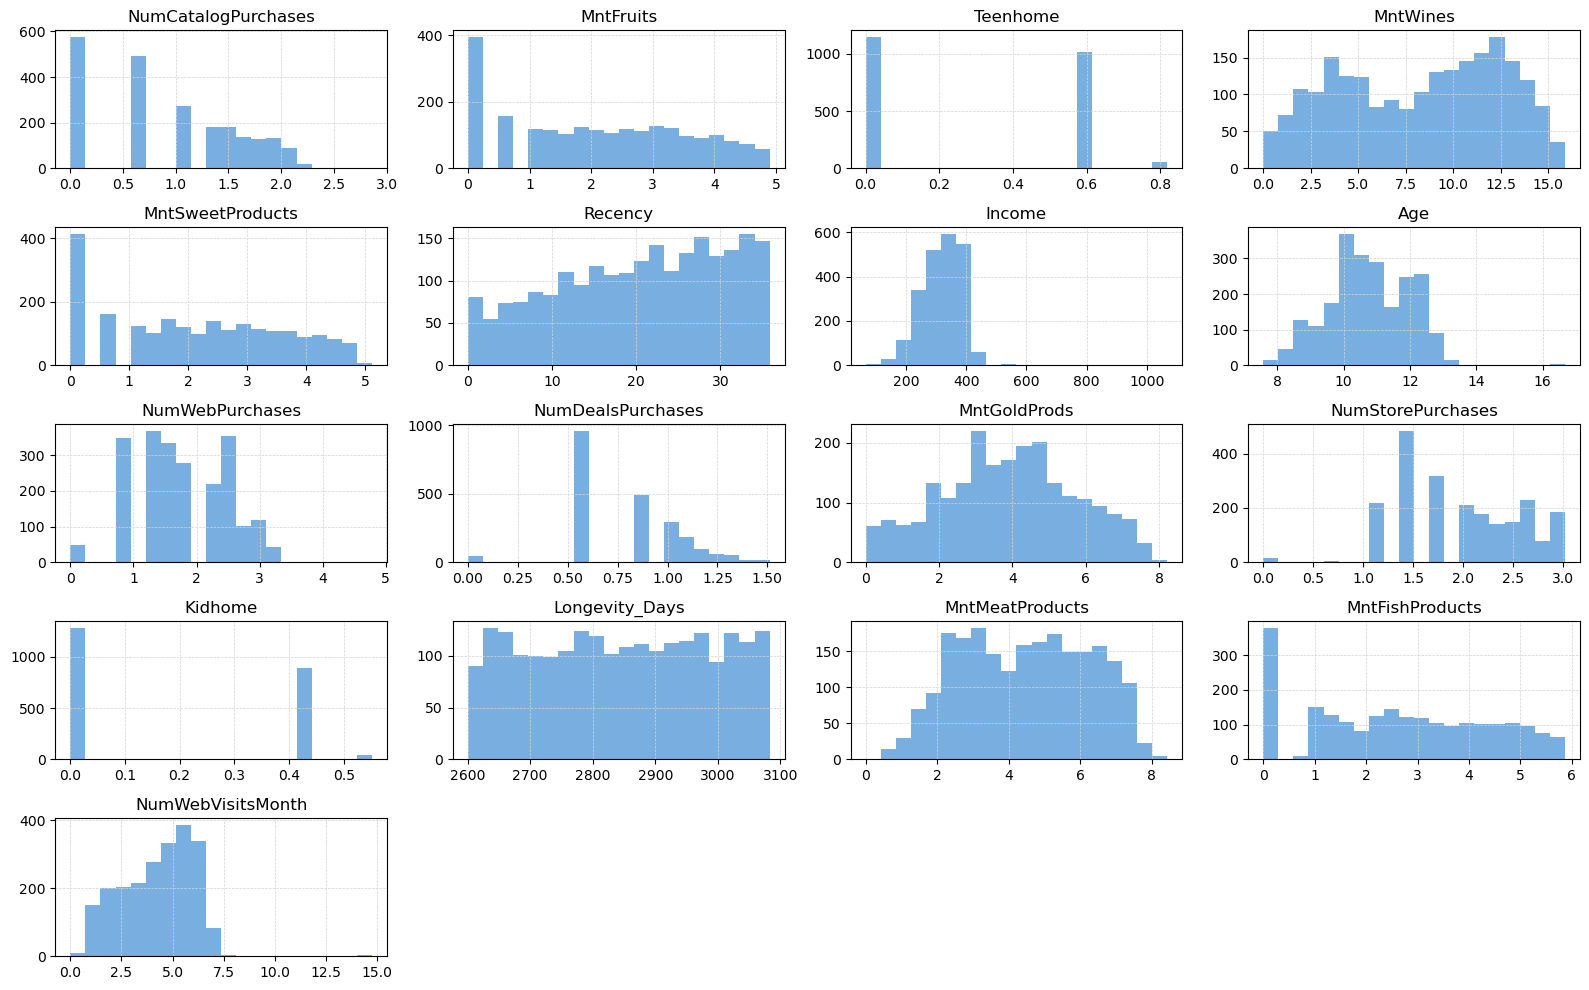

In [35]:
# # Histogram after transformation
# df_transformed.hist(figsize=(20, 15), bins=20, layout=(5, 4))

# plt.tight_layout()
# plt.show()


hist_color = '#79afe0' #'#a1c7e9' # '#79afe0' # 

# Plotting the histograms
axes = df_transformed.hist(figsize=(16, 10), bins=20, layout=(5, 4), color=hist_color)

# Customizing each subplot in the figure
for ax in axes.flatten():
    if ax is not None:
        ax.grid(True, linestyle='--', linewidth=0.5, color='lightgrey')  # Adding grid with specified color

plt.tight_layout()
plt.show()

**Remove Outliers: Use Quartile transformation**

In [36]:
# Assuming df_transformed is your DataFrame after transformations
Q1 = df_transformed.quantile(0.25)
Q3 = df_transformed.quantile(0.75)
IQR = Q3 - Q1

# Identifying rows with outliers
outliers = ((df_transformed < (Q1 - 1.5 * IQR)) | (df_transformed > (Q3 + 1.5 * IQR))).any(axis=1)

# Filtering out the outliers
df_no_outliers = df_transformed[~outliers]

print(f"Original DataFrame shape: {df_transformed.shape}")
print(f"New DataFrame shape (after removing outliers): {df_no_outliers.shape}")

Original DataFrame shape: (2216, 17)
New DataFrame shape (after removing outliers): (2192, 17)


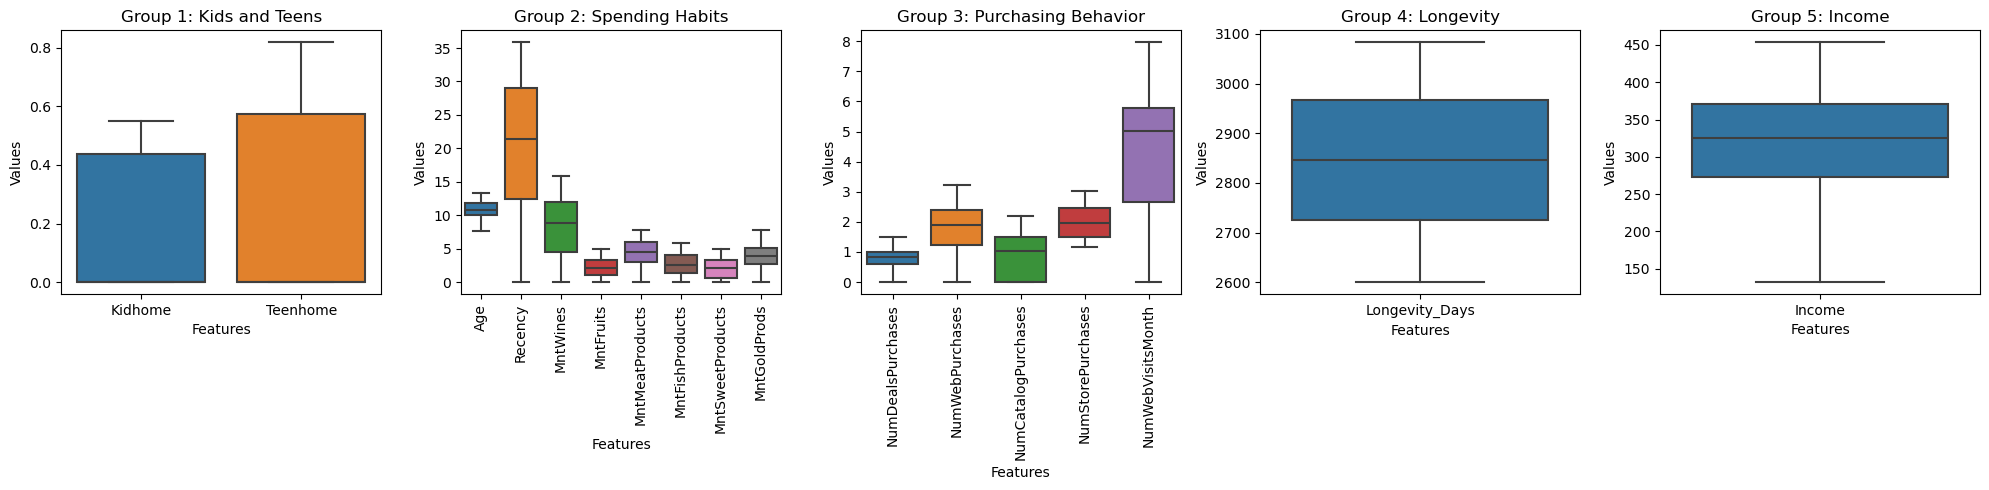

In [37]:

# Creating separate DataFrames for each group
dfs = [
    df_no_outliers[cont_pred_list1],
    df_no_outliers[cont_pred_list2],
    df_no_outliers[cont_pred_list3],
    df_no_outliers[cont_pred_list4],
    df_no_outliers[cont_pred_list5]
]
 
# Group lists and their labels for titles
groups = [
    ('Group 1: Kids and Teens', ['Kidhome', 'Teenhome']),
    ('Group 2: Spending Habits', ['Age', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']),
    ('Group 3: Purchasing Behavior', ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']),
    ('Group 4: Longevity', ['Longevity_Days']),
    ('Group 5: Income', ['Income'])
]

# Plotting
fig, axes = plt.subplots(1, 5, figsize=(20, 5))  # One subplot per group 
for ax, (title, features) in zip(axes, groups):
    sns.boxplot(data=df_no_outliers[features], ax=ax)
    rotate_num = 90 if len(features) > 3 else 0
    ax.set_xticklabels(ax.get_xticklabels(), rotation=rotate_num)  # Rotate x labels for better visibility
    ax.set_title(title)  # Use pre-defined titles
    ax.set_xlabel('Features')
    ax.set_ylabel('Values')

plt.tight_layout()
plt.show()

In [38]:
# df_continuous3 = df_no_outliers[['Income', 'Age', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts']]
# df_continuous3.head()

In [39]:
# #Boxplot after transformation
# plt.figure(figsize=(15, 8))  # Set the figure size
# sns.boxplot(data=df_continuous3)
# plt.title('Boxplot for Continuous Predictors')  # Title for the boxplot
# plt.ylabel('Values')  # Y-axis label
# plt.xlabel('Features')  # X-axis label
# plt.show() 

In [40]:
# df_continuous4 = df_no_outliers[['MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 
#                                 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']]
# df_continuous4.head()

In [41]:
# #Boxplots after trasmormation

# plt.figure(figsize=(15, 8))  # Set the figure size
# sns.boxplot(data=df_continuous4)
# plt.title('Boxplot for Continuous Predictors')  # Title for the boxplot
# plt.ylabel('Values')  # Y-axis label
# plt.xlabel('Features')  # X-axis label
# plt.show() 

In [42]:
## 
df_cont_trans = df_no_outliers 
df_cont_trans

,NumCatalogPurchases,MntFruits,Teenhome,MntWines,MntSweetProducts,Recency,Income,Age,NumWebPurchases,NumDealsPurchases,MntGoldProds,NumStorePurchases,Kidhome,Longevity_Days,MntMeatProducts,MntFishProducts,NumWebVisitsMonth
0,2.133795,4.199126,0.00000,12.705328,4.186754,24.188076,343.811981,11.953224,2.775587,1.004241,5.888203,1.744995,0.000000,3058.070411,7.000696,5.412924,5.779540
1,0.669832,0.685979,0.57373,3.178017,0.685661,17.656296,309.359816,12.220869,0.744814,0.848214,2.182842,1.160694,0.438488,2678.788332,2.009098,1.110111,4.259654
2,1.040811,3.690869,0.00000,11.392981,2.945816,13.266679,378.840296,11.204791,2.775587,0.587106,4.714454,2.707019,0.000000,2816.293254,5.257759,4.935562,3.473617
3,0.000000,1.571145,0.00000,3.178017,1.356564,13.266679,238.988268,9.160636,1.232167,0.848214,1.991404,1.744995,0.438488,2696.772269,3.201087,2.453130,5.027298
4,1.295112,3.576993,0.00000,8.776827,3.163852,34.517856,344.238416,9.514894,2.165126,1.189755,3.269942,2.146354,0.438488,2711.985049,5.172430,3.993869,4.259654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1.295112,3.576993,0.57373,13.085786,4.437917,20.363610,352.187575,11.008912,2.942698,0.848214,7.719029,1.744995,0.000000,2863.896562,5.679073,3.898280,4.259654
2236,1.040811,0.000000,0.57373,11.241582,0.000000,23.567497,359.571643,12.904519,2.775587,1.300611,2.502376,1.960813,0.551680,2613.721886,3.634032,0.000000,5.779540
2237,1.295112,3.672902,0.00000,13.969471,2.464407,33.706676,340.609369,9.514894,1.232167,0.587106,3.901583,3.016610,0.000000,2707.836507,5.887148,3.614773,5.027298
2238,1.641416,3.262777,0.57373,11.407803,3.255379,5.307334,372.958984,12.043173,2.391254,0.848214,5.292534,2.707019,0.000000,2708.527951,5.870629,4.582332,2.664875


**Removing high corr by threshold 0.85**

Using PCA instead to reduce the dimensions... but only after splitting the data

In [43]:
# # Calculate the correlation matrix
# corr_matrix = df_cont_trans.corr().abs()

# # Select upper triangle of correlation matrix
# upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# # Find features with correlation greater than 0.85
# to_drop = [column for column in upper.columns if any(upper[column] > 0.75)]

# # Drop features
# df_cont_reduced = df_cont_trans.drop(to_drop, axis=1)

# # print(f"Columns to drop: {to_drop}")
# # print("Reduced DataFrame:")
# # print(df_cont_reduced.head())

# # # after trx
# # correlation_matrix = df_cont_reduced.corr()
# # plt.figure(figsize=(8, 6))
# # sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f")
# # plt.title('Correlation Matrix')
# # plt.show()



# # import seaborn as sns
# # import matplotlib.pyplot as plt
# # import pandas as pd
# from scipy.cluster.hierarchy import dendrogram, linkage

# # # Calculate the correlation matrix
# corr_matrix = df_cont_reduced.corr()

# # Compute the linkage matrix using Ward's method
# link = linkage(corr_matrix, method='ward')

# # Reorder the correlation matrix based on the linkage
# dendro = dendrogram(link, labels=corr_matrix.columns, no_plot=True)
# order = dendro['leaves']
# corr_ordered = corr_matrix.iloc[order, :].iloc[:, order]

# # Create the heatmap with the reordered correlation matrix
# plt.figure(figsize=(8, 6))
# sns.heatmap(corr_ordered, annot=False, cmap='coolwarm', fmt=".2f",
#             linewidths=.5, cbar_kws={"shrink": .5})
# plt.title('Clustered Correlation Matrix')
# plt.xticks(rotation=90)
# plt.yticks(rotation=0)
# plt.show()


# print(df_cont_reduced.shape)

In [44]:
# just to reassing...
df_cont_reduced = df_cont_trans

In [45]:
# pd.DataFrame(c_seg_final).isnull().sum()
df_cont_reduced.isnull().sum()

NumCatalogPurchases    0
MntFruits              0
Teenhome               0
MntWines               0
MntSweetProducts       0
Recency                0
Income                 0
Age                    0
NumWebPurchases        0
NumDealsPurchases      0
MntGoldProds           0
NumStorePurchases      0
Kidhome                0
Longevity_Days         0
MntMeatProducts        0
MntFishProducts        0
NumWebVisitsMonth      0
dtype: int64

**Applying PCA--dimensionality reduction instead of removing high corr by threshold**

In [46]:
# pca = PCA()
# pca.fit(df_cont_trans.iloc[:,:])

# print("Per Variable Mean used to Center Data")
# print(pca.mean_)

In [47]:
# print("principal components")
# print(pca.components_)
# print("\nsingular values")
# print(pca.singular_values_)
# print("\nexplained variance ratio")
# print(pca.explained_variance_ratio_)

In [48]:
# #Preprocessing cont.

# #Final handling of missing values
# imputer = SimpleImputer(strategy='median')
# df_final_imputed = imputer.fit_transform(df_final)
# #Scaling the data
# scaler = StandardScaler()
# df_scaled = scaler.fit_transform(df_final_imputed)

In [49]:
# # Applying PCA and specifying n_components to 2 to retain the first two components
# pca = PCA(n_components=1)
# pca.fit(df_scaled)

# # The variance explained by the first two components
# variance_explained = pca.explained_variance_ratio_

# variance_explained.sum(), variance_explained

In [50]:
# pca = PCA(n_components=1) 
# df_pca = pca.fit_transform(df_scaled)

In [51]:
# # Applying PCA without specifying n_components to retain all components
# pca = PCA(n_components=2)
# pca.fit(df_scaled)

# # Explained variance ratios
# explained_variance = pca.explained_variance_ratio_

# # Creating a scree plot
# plt.figure(figsize=(10, 6))
# plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
# plt.title('Scree Plot')
# plt.xlabel('Number of Components')
# plt.ylabel('Variance Explained')
# plt.xticks(range(1, len(explained_variance) + 1))  # Adding 1 because range doesn’t include the last number
# plt.grid(True)

# # Optional: Cumulative Variance Explained
# plt.figure(figsize=(10, 6))
# plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), marker='o', linestyle='--')
# plt.title('Cumulative Variance Explained by PCA Components')
# plt.xlabel('Number of Components')
# plt.ylabel('Cumulative Variance Explained')
# plt.xticks(range(1, len(explained_variance) + 1))
# plt.grid(True)

# plt.show()

**Encode Education and Marital_Status columns: to dummy variables**

In [52]:
print('cat before:', df_categorical.shape)

df_categorical.info()

cat before: (2216, 8)
<class 'pandas.core.frame.DataFrame'>
Index: 2216 entries, 0 to 2239
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Education       2216 non-null   object
 1   Marital_Status  2216 non-null   object
 2   AcceptedCmp3    2216 non-null   int64 
 3   AcceptedCmp4    2216 non-null   int64 
 4   AcceptedCmp5    2216 non-null   int64 
 5   AcceptedCmp1    2216 non-null   int64 
 6   AcceptedCmp2    2216 non-null   int64 
 7   Complain        2216 non-null   int64 
dtypes: int64(6), object(2)
memory usage: 155.8+ KB


In [53]:
# pd.DataFrame(c_seg_final).isnull().sum()
df_categorical.isnull().sum()

Education         0
Marital_Status    0
AcceptedCmp3      0
AcceptedCmp4      0
AcceptedCmp5      0
AcceptedCmp1      0
AcceptedCmp2      0
Complain          0
dtype: int64

In [54]:
# Converting 'Education' and 'Marital_Status' columns to dummy variables
education_dummies = pd.get_dummies(df_categorical['Education'], prefix='Education')
marital_status_dummies = pd.get_dummies(df_categorical['Marital_Status'], prefix='Marital_Status')

# Concatenate the dummy variables with the original DataFrame
df_categorical_new = pd.concat([df_categorical, education_dummies, marital_status_dummies], axis=1)

df_categorical_new.head()

,Education,Marital_Status,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Education_2n Cycle,Education_Basic,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,Graduation,Single,0,0,0,0,0,0,False,False,...,False,False,False,False,False,False,True,False,False,False
1,Graduation,Single,0,0,0,0,0,0,False,False,...,False,False,False,False,False,False,True,False,False,False
2,Graduation,Together,0,0,0,0,0,0,False,False,...,False,False,False,False,False,False,False,True,False,False
3,Graduation,Together,0,0,0,0,0,0,False,False,...,False,False,False,False,False,False,False,True,False,False
4,PhD,Married,0,0,0,0,0,0,False,False,...,False,True,False,False,False,True,False,False,False,False


In [55]:
# Drop the original 'Education' and 'Marital_Status' columns
df_categorical_final = df_categorical_new.drop(['Education', 'Marital_Status'], axis=1) 
df_categorical_final = df_categorical_final.astype(int)
# df_categorical_final = df_categorical_final.applymap(int)
df_categorical_final.head()

,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0


In [56]:
print('cat after:', df_categorical_final.shape)
print('cont:', df_cont_reduced.shape)

cat after: (2216, 19)
cont: (2192, 17)


In [57]:
# pd.DataFrame(c_seg_final).isnull().sum()
df_categorical_final.isnull().sum()
# print(df_categorical_final.shape)
df_categorical_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2216 entries, 0 to 2239
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   AcceptedCmp3             2216 non-null   int64
 1   AcceptedCmp4             2216 non-null   int64
 2   AcceptedCmp5             2216 non-null   int64
 3   AcceptedCmp1             2216 non-null   int64
 4   AcceptedCmp2             2216 non-null   int64
 5   Complain                 2216 non-null   int64
 6   Education_2n Cycle       2216 non-null   int64
 7   Education_Basic          2216 non-null   int64
 8   Education_Graduation     2216 non-null   int64
 9   Education_Master         2216 non-null   int64
 10  Education_PhD            2216 non-null   int64
 11  Marital_Status_Absurd    2216 non-null   int64
 12  Marital_Status_Alone     2216 non-null   int64
 13  Marital_Status_Divorced  2216 non-null   int64
 14  Marital_Status_Married   2216 non-null   int64
 15  Marital_S

**Join the categorical and the continuous dfs...**

In [58]:
# df_categorical_final.isnull().sum()
# df_cont_reduced.isnull().sum()
print(df_categorical_final.shape)
print(df_cont_reduced.shape)

(2216, 19)
(2192, 17)


In [59]:
df_response.shape

(2216,)

In [60]:
# removing the outliers dropped some samples from continuous data
# combine the dfs... then remove all nulls again...
# this will handle the mistched... resulting in nulls ... 24 rows

# add the response label and drop the column again

c_seg_final = pd.concat([df_categorical_final, df_cont_reduced, df_response], axis=1)
c_seg_final.head()
print(c_seg_final.shape)

(2216, 37)


In [61]:
c_seg_final.isnull().sum()

AcceptedCmp3                0
AcceptedCmp4                0
AcceptedCmp5                0
AcceptedCmp1                0
AcceptedCmp2                0
Complain                    0
Education_2n Cycle          0
Education_Basic             0
Education_Graduation        0
Education_Master            0
Education_PhD               0
Marital_Status_Absurd       0
Marital_Status_Alone        0
Marital_Status_Divorced     0
Marital_Status_Married      0
Marital_Status_Single       0
Marital_Status_Together     0
Marital_Status_Widow        0
Marital_Status_YOLO         0
NumCatalogPurchases        24
MntFruits                  24
Teenhome                   24
MntWines                   24
MntSweetProducts           24
Recency                    24
Income                     24
Age                        24
NumWebPurchases            24
NumDealsPurchases          24
MntGoldProds               24
NumStorePurchases          24
Kidhome                    24
Longevity_Days             24
MntMeatPro

In [62]:

#Dropping the missing values in the Income column
c_seg_final = c_seg_final.dropna() #subset=['MntFruits'] all rows with na ...

c_seg_final.shape
# c_seg_final.isnull().sum()

(2192, 37)

In [63]:
df_response = c_seg_final['Response']
c_seg_final.drop('Response', axis=1, inplace=True)

In [64]:
print(df_response.shape)
print(c_seg_final.shape)

(2192,)
(2192, 36)


### Data Partition. Splitting the Data >> train, val, test. Note: cat + cont

Clustering is unsupervised. We do not need the validation set here to avoid overfittig the model during training. Instead, we would require more of the data to understand the internal pattern. **Use: train (80%)+ test (20%)**

In [65]:

rnd_stat = 5831

# # Split of the test set
# X_trainval, X_test, y_trainval, y_test = train_test_split(c_seg_final, df_response, test_size = 0.2, random_state = rnd_stat, stratify=df_response) # f_cont_trans['Response'])

# # Split trainval into train + val ...20/80 =25%
# X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size = 0.25, random_state = rnd_stat, stratify=y_trainval)


# split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(c_seg_final, df_response, test_size=0.20, random_state=rnd_stat, stratify=df_response)


print('orig -- X -- y')
print(c_seg_final.shape)
print(df_response.shape)
print('test')
# print(X_trainval.shape)
# print(y_trainval.shape)
print(X_test.shape)
print(y_test.shape)
print('train')
print(X_train.shape)
print(y_train.shape)
# print(X_val.shape)
# print(y_val.shape)


orig -- X -- y
(2192, 36)
(2192,)
test
(439, 36)
(439,)
train
(1753, 36)
(1753,)


**Scaling the Data**

We will scale the data when fitting within the CV...

In [66]:
# #use training data set to set scaling parameters
# scaler = StandardScaler().fit(X_train) 
# X_train_sc = scaler.transform(X_train)
# X_val_sc = scaler.transform(X_val)

# #use the train+val to scale the train+val data
# scaler_final = StandardScaler().fit(X_trainval) 
# X_trainval_sc = scaler_final.transform(X_trainval)
# X_test_sc = scaler_final.transform(X_test)


# define the scaler
scaler = MinMaxScaler() # StandardScaler()
scaler.fit(X_train) # fit on the training dataset
X_train_sc = scaler.transform(X_train) # scale the training dataset

# scale the test dataset, using the parameters from train data X_test = scaler.transform(X_test)
X_test_sc = scaler.transform(X_test)


**Applying PCA to reduce the dimensions**

**Prior to Applying PCA: Dimensions**

In [67]:
c_seg_final.columns

Index(['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Education_2n Cycle', 'Education_Basic',
       'Education_Graduation', 'Education_Master', 'Education_PhD',
       'Marital_Status_Absurd', 'Marital_Status_Alone',
       'Marital_Status_Divorced', 'Marital_Status_Married',
       'Marital_Status_Single', 'Marital_Status_Together',
       'Marital_Status_Widow', 'Marital_Status_YOLO', 'NumCatalogPurchases',
       'MntFruits', 'Teenhome', 'MntWines', 'MntSweetProducts', 'Recency',
       'Income', 'Age', 'NumWebPurchases', 'NumDealsPurchases', 'MntGoldProds',
       'NumStorePurchases', 'Kidhome', 'Longevity_Days', 'MntMeatProducts',
       'MntFishProducts', 'NumWebVisitsMonth'],
      dtype='object')

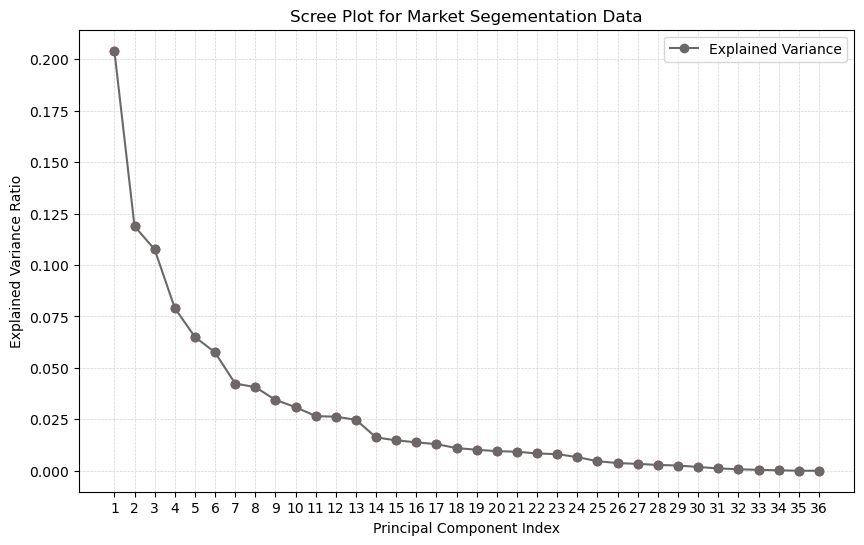

In [68]:
 
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Initialize PCA
pca = PCA()

# Fit PCA on the scaled training data
pca.fit(X_train_sc)

# Get the explained variance ratio
explained_variance = pca.explained_variance_ratio_

# Create a scree plot using dots connected by lines
plt.figure(figsize=(10, 6))
components = range(1, len(explained_variance) + 1)
plt.plot(components, explained_variance, '-o', label='Explained Variance', color='dimgrey')  # Line with dots
plt.scatter(components, explained_variance, color='r')  # Red dots

plt.title('Scree Plot for Market Segementation Data')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.xticks(components)  # Set x-ticks to match the number of components
plt.legend()

# Enable horizontal grid lines only
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

plt.show()



**Applying PCA to reduce the dimensions**

Retain: 12 components

In [69]:
# Initialize PCA with the decided number of components
pca = PCA(n_components=12)

# Fit PCA on the training data only
pca.fit(X_train_sc)

# Apply the transformation to the training data
X_train_pca = pca.transform(X_train_sc)

# Apply the same transformation to the test data
X_test_pca = pca.transform(X_test_sc)



# Convert the PCA results into a DataFrame
df_pca_cols = ['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Education_2n Cycle', 'Education_Basic', 'Education_Graduation', 'Education_Master', 'Education_PhD', 'Marital_Status_Absurd', 'Marital_Status_Alone', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow', 'Marital_Status_YOLO', 'MntGoldProds', 'Age', 'MntFruits', 'Income', 'MntSweetProducts', 'NumWebVisitsMonth', 'NumCatalogPurchases', 'MntWines', 'MntFishProducts', 'MntMeatProducts', 'Longevity_Days', 'Recency', 'NumDealsPurchases', 'Teenhome', 'NumStorePurchases', 'Kidhome', 'NumWebPurchases']
df_X_test_pca = pd.DataFrame(X_train_pca, columns=df_pca_cols[0:12])

In [70]:
# df_pca_cols = ['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Education_2n Cycle', 'Education_Basic', 'Education_Graduation', 'Education_Master', 'Education_PhD', 'Marital_Status_Absurd', 'Marital_Status_Alone', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow', 'Marital_Status_YOLO', 'MntGoldProds', 'Age', 'MntFruits', 'Income', 'MntSweetProducts', 'NumWebVisitsMonth', 'NumCatalogPurchases', 'MntWines', 'MntFishProducts', 'MntMeatProducts', 'Longevity_Days', 'Recency', 'NumDealsPurchases', 'Teenhome', 'NumStorePurchases', 'Kidhome', 'NumWebPurchases']
# df_pca_cols[0:12]

In [71]:
# from sklearn.decomposition import PCA
# import matplotlib.pyplot as plt

# # Initialize PCA
# pca = PCA()

# # Fit PCA on the scaled training data
# pca.fit(X_train_sc)

# # Get the explained variance ratio
# explained_variance = pca.explained_variance_ratio_

# # Create a simple scree plot
# plt.figure(figsize=(10, 6))
# plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.6, align='center', color='b')
# plt.ylabel('Explained Variance Ratio')
# plt.xlabel('Principal Component Index')
# plt.title('Scree Plot')
# plt.xticks(ticks=range(1, len(explained_variance) + 1))  # Set x-ticks to match the number of components
# plt.show()


### Build the Models

['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Education_2n Cycle', 'Education_Basic',
       'Education_Graduation', 'Education_Master', 'Education_PhD',
       'Marital_Status_Absurd', 'Marital_Status_Alone',
       'Marital_Status_Divorced', 'Marital_Status_Married',
       'Marital_Status_Single', 'Marital_Status_Together',
       'Marital_Status_Widow', 'Marital_Status_YOLO', 'MntGoldProds', 'Age',
       'MntFruits', 'Income', 'MntSweetProducts', 'NumWebVisitsMonth',
       'NumCatalogPurchases', 'MntWines', 'MntFishProducts', 'MntMeatProducts',
       'Longevity_Days', 'Recency', 'NumDealsPurchases', 'Teenhome',
       'NumStorePurchases', 'Kidhome', 'NumWebPurchases']

**Choosing the best K (Clusters)**

From the plots below, the best K = 8

within-cluster sse:
 [3508.117861908647, 3160.82085464398, 2906.0785977332594, 2719.554534048322, 2553.3708258275274, 2412.3426130383846, 2280.3878206401755, 2194.8751649860374, 2088.1341279165085]
dbscore:
 [1.9930157067896928, 2.0680638540506364, 2.1589436887059366, 1.9829660646428047, 1.9093756912135103, 1.8616924428810873, 1.7176102617120268, 1.763750833836732, 1.4967852308207463]
chscore:
 [429.43392374455925, 334.3178406496682, 293.37939642802024, 264.9636525614502, 248.37805659308685, 235.9688699260801, 228.26515346505798, 215.88799015218657, 211.49415789972025]
silh_scores:
 [0.18406898381229356, 0.16266004487067026, 0.1536941914605126, 0.17453114792618413, 0.16629622362154112, 0.18773675121831127, 0.19458466425569573, 0.18060979135126795, 0.20232945880255668]


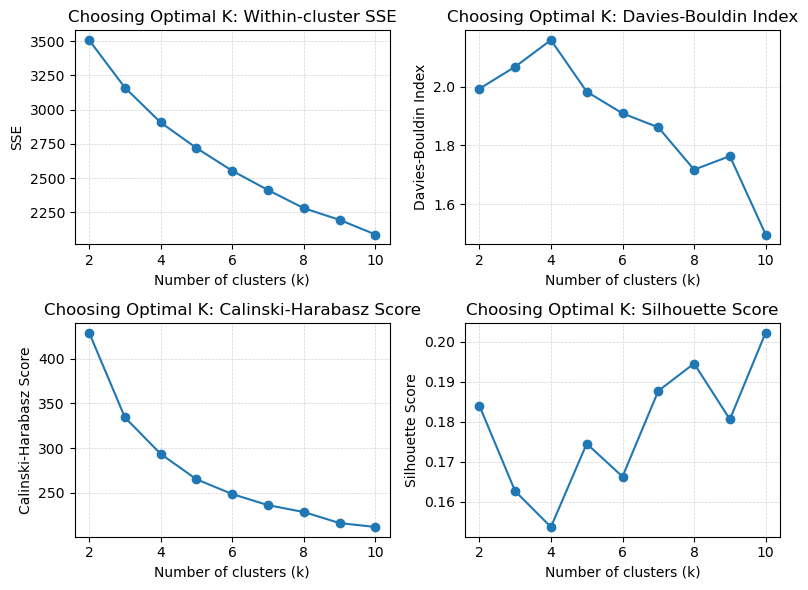

In [72]:

sse = [] # within-cluster variation, “inertia” and total “within-cluster sum-of-squares”
dbscore = [] # lower values indicate compact and better clustered data
chscore = [] # higher values ...
silh_scores = []

k_values = range(2, 11) # k= 2, . . . , 12
rnd_stat_mdl = 42
# n_init_val = 10 # diff from n_iter_ ...which is not predetermined

for k in k_values:
    # Perform KMeans clustering
    kmeans = cluster.KMeans(n_clusters=k, n_init=10, random_state=rnd_stat_mdl)
    kmeans.fit(X_train_pca)

    # kmeans = KMeans(n_clusters=K, init='k-means++', n_init=10, max_iter=300, random_state=rnd_stat_mdl)
    # kmeans.fit(X_train_pca)  # Fit on the scaled training data
    
    # within-cluster variation, “inertia” and total “within-cluster sum-of-squares”
    sse.append(kmeans.inertia_)
    
    # the Davies-Bouldin index
    dbscore.append(metrics.davies_bouldin_score(X_train_pca, kmeans.labels_))
    
    # the Calinski-Harabasz score
    chscore.append(metrics.calinski_harabasz_score(X_train_pca, kmeans.labels_))

    # Note: Silhouette score can be computationally expensive for very large datasets
    silh_scores.append(metrics.silhouette_score(X_train_pca, kmeans.labels_))

 
print('within-cluster sse:\n', sse)
print('dbscore:\n', dbscore)
print('chscore:\n', chscore)
print('silh_scores:\n', silh_scores)


# keep track of the within-cluster variation...
# the Calinski-Harabasz score, and the Davies-Bouldin index on the resulting clusters.
# use plots... visualize

plt.figure(figsize=(8, 6))

# Subplot for Within-cluster SSE
plt.subplot(2, 2, 1)  # First subplot in a 2x2 grid
plt.plot(k_values, sse, '-o')
plt.title('Choosing Optimal K: Within-cluster SSE')
plt.xlabel('Number of clusters (k)')
plt.ylabel('SSE')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Subplot for Davies-Bouldin Index
plt.subplot(2, 2, 2)  # Second subplot in a 2x2 grid
plt.plot(k_values, dbscore, '-o')
plt.title('Choosing Optimal K: Davies-Bouldin Index')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Subplot for Calinski-Harabasz Score
plt.subplot(2, 2, 3)  # Third subplot in a 2x2 grid
plt.plot(k_values, chscore, '-o')
plt.title('Choosing Optimal K: Calinski-Harabasz Score')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Calinski-Harabasz Score')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Subplot for Silhouette Score
plt.subplot(2, 2, 4)  # Fourth subplot in a 2x2 grid
plt.plot(k_values, silh_scores, '-o')
plt.title('Choosing Optimal K: Silhouette Score')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)
 

# Adjust layout to prevent overlap and ensure clear presentation
plt.tight_layout()


# Show the plot
plt.show()

 

In [73]:
best_k = 8

pca1 = 'PCA 1 (~' + str(df_pca_cols[0]) + ')'
pca2 = 'PCA 2 (~' + str(df_pca_cols[1]) + ')'
pca1

'PCA 1 (~AcceptedCmp3)'

In [74]:

# # Assume X_train has been scaled and is stored in X_train_sc
# # Assume X_test has been scaled and is stored in X_test_sc

# # Elbow Method
# inertias = []
# silhouette_scores = []

# rnd_stat_mdl = 42
# # Define the range of K to try
# K_range = range(2, 11)  # Adjust upper limit as needed

# for K in K_range:
#     kmeans = KMeans(n_clusters=K, init='k-means++', n_init=10, max_iter=300, random_state=rnd_stat_mdl)
#     kmeans.fit(X_train_sc)  # Fit on the scaled training data
    
#     # Append the inertia to the list of inertias
#     inertias.append(kmeans.inertia_)
    
#     # Compute the silhouette score and append it to the list
#     # Note: Silhouette score can be computationally expensive for very large datasets
#     silhouette_scores.append(silhouette_score(X_train_sc, kmeans.labels_))



# # Setting up the figure and axes for subplots
# fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))  # One row, two columns

# # Plot the Elbow Plot on the first subplot
# axes[0].plot(K_range, inertias, '-o')
# axes[0].set_title('Elbow Method to Determine Optimal K')
# axes[0].set_xlabel('Number of clusters, K')
# axes[0].set_ylabel('Inertia')
# axes[0].set_xticks(K_range)

# # Plot the Silhouette Scores on the second subplot
# axes[1].plot(K_range, silhouette_scores, '-o')
# axes[1].set_title('Silhouette Score to Determine Optimal K')
# axes[1].set_xlabel('Number of clusters, K')
# axes[1].set_ylabel('Silhouette Score')
# axes[1].set_xticks(K_range)

# # Tight layout to ensure there's no overlap
# plt.tight_layout()

# # Display the plots
# plt.show()


**Train models... Cluster Algorithms**

**K-Means Clustering**

/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Iteration 1: Silhouette Coefficient = 0.19889231724267586, Calinski-Harabasz Index = 185.09987949640706, Davies-Bouldin Index = 1.7424382462514378
Iteration 2: Silhouette Coefficient = 0.19606038009784865, Calinski-Harabasz Index = 179.84977242018388, Davies-Bouldin Index = 1.634543092397652


/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Iteration 3: Silhouette Coefficient = 0.18633045820560193, Calinski-Harabasz Index = 191.56464968120747, Davies-Bouldin Index = 1.6955673469946193
Iteration 4: Silhouette Coefficient = 0.20550360878333507, Calinski-Harabasz Index = 195.70295042790303, Davies-Bouldin Index = 1.7296866633896653


/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


...

/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Iteration 7: Silhouette Coefficient = 0.19879217501814048, Calinski-Harabasz Index = 177.75739099235304, Davies-Bouldin Index = 1.6710420396236327
Iteration 8: Silhouette Coefficient = 0.19715620892682512, Calinski-Harabasz Index = 185.51736654864422, Davies-Bouldin Index = 1.7494884347038964


/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Iteration 9: Silhouette Coefficient = 0.1983949437608481, Calinski-Harabasz Index = 177.6502781395742, Davies-Bouldin Index = 1.6451048754203934
Iteration 10: Silhouette Coefficient = 0.17962033799717997, Calinski-Harabasz Index = 179.52764407588413, Davies-Bouldin Index = 1.7321449060040406
Optimal Silhouette Score: 0.20550360878333507
Optimal Calinski-Harabasz Index: 195.70295042790303
Optimal Davies-Bouldin Index: 1.634543092397652


/opt/anaconda3/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


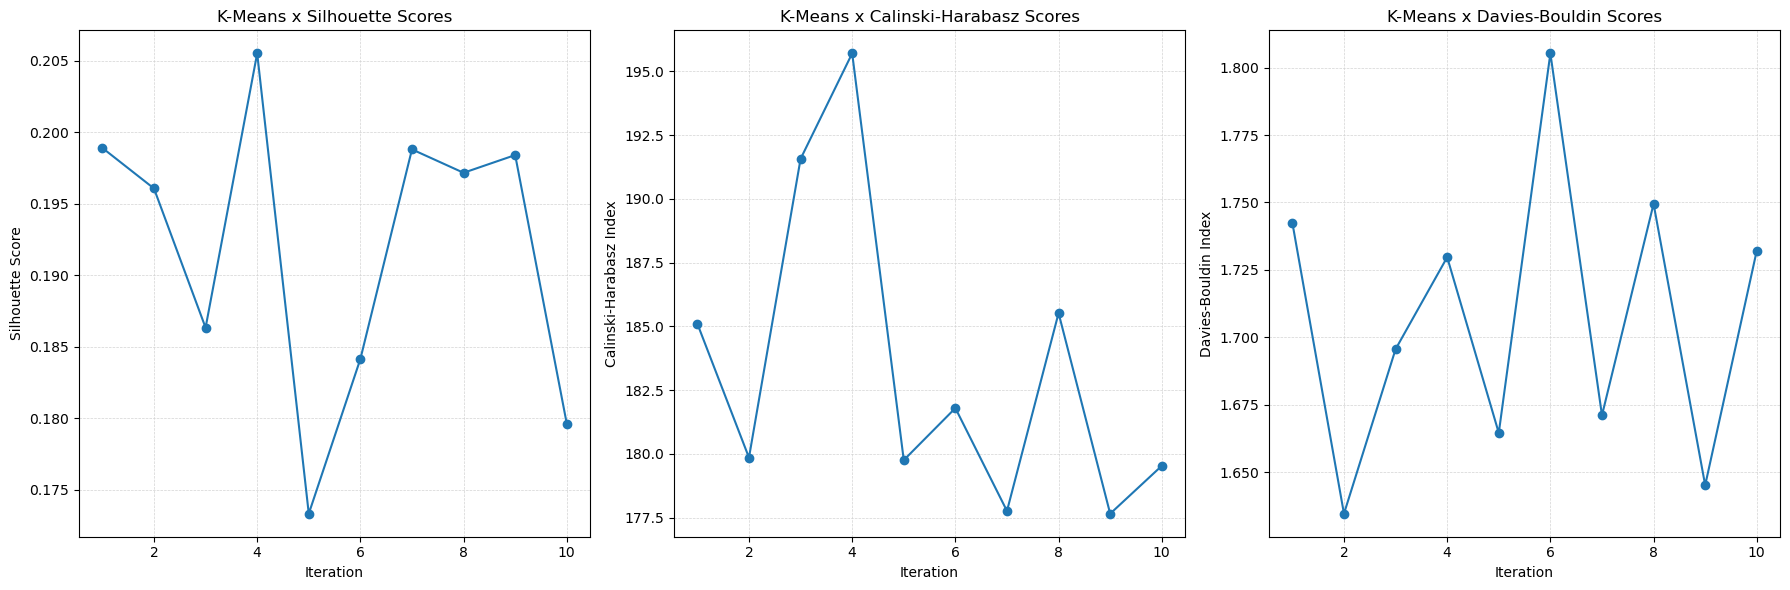

In [75]:
 
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.utils import resample 

# Assuming best_k has been defined based on your analysis
# best_k = 6  # Replace with your actual best_k value
num_iterations = 10  # Number of bootstrapping iterations
silhouette_scores = []
calinski_scores = []
davies_scores = []

for i in range(num_iterations):
    # Resample the data to create a bootstrap sample
    X_boot = resample(X_train_pca, n_samples=int(len(X_train_pca) * 0.8))
    
    # Initialize and fit KMeans
    kmeans = KMeans(n_clusters=best_k, random_state=42)
    kmeans.fit(X_boot)
    
    # Predict the cluster labels for the bootstrapped PCA-transformed training data
    train_labels = kmeans.predict(X_boot)

    # Silhouette Coefficient
    silhouette_avg = silhouette_score(X_boot, train_labels)
    silhouette_scores.append(silhouette_avg)
    
    # Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(X_boot, train_labels)
    calinski_scores.append(calinski_harabasz)
    
    # Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(X_boot, train_labels)
    davies_scores.append(davies_bouldin)
    
    print(f'Iteration {i+1}: Silhouette Coefficient = {silhouette_avg}, Calinski-Harabasz Index = {calinski_harabasz}, Davies-Bouldin Index = {davies_bouldin}')

# Find optimal scores
max_silhouette = max(silhouette_scores)
max_calinski = max(calinski_scores)
min_davies = min(davies_scores)

print(f'Optimal Silhouette Score: {max_silhouette}')
print(f'Optimal Calinski-Harabasz Index: {max_calinski}')
print(f'Optimal Davies-Bouldin Index: {min_davies}')

# Plotting all metrics as subplots
plt.figure(figsize=(18, 6))

# Silhouette Scores
plt.subplot(1, 3, 1)
plt.plot(range(1, len(silhouette_scores) + 1), silhouette_scores, marker='o', linestyle='-')
plt.title('K-Means x Silhouette Scores')
plt.xlabel('Iteration')
plt.ylabel('Silhouette Score')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Calinski-Harabasz Scores
plt.subplot(1, 3, 2)
plt.plot(range(1, len(calinski_scores) + 1), calinski_scores, marker='o', linestyle='-')
plt.title('K-Means x Calinski-Harabasz Scores')
plt.xlabel('Iteration')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Davies-Bouldin Scores
plt.subplot(1, 3, 3)
plt.plot(range(1, len(davies_scores) + 1), davies_scores, marker='o', linestyle='-')
plt.title('K-Means x Davies-Bouldin Scores')
plt.xlabel('Iteration')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


In [76]:

# from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score


# # ... (assuming X_train_pca is your PCA-transformed training data)

# # Determine the number of clusters from your KMeans analysis (let's say 6 is optimal here)
# # num_clusters = best_k  # replace with your actual best_k value

# # Cluster using the PCA-transformed data
# kmeans = KMeans(n_clusters=best_k, random_state=42)
# kmeans.fit(X_train_pca)

# # Predict the cluster labels for the PCA-transformed training data
# train_labels = kmeans.predict(X_train_pca)

# # Inertia (within-cluster sum of squares)
# inertia = kmeans.inertia_
# print(f'Inertia: {inertia}')

# # Silhouette Coefficient
# silhouette_avg = silhouette_score(X_train_pca, train_labels)
# print(f'Silhouette Coefficient: {silhouette_avg}')

# # Calinski-Harabasz Index
# calinski_harabasz = calinski_harabasz_score(X_train_pca, train_labels)
# print(f'Calinski-Harabasz Index: {calinski_harabasz}')

# # Davies-Bouldin Index
# davies_bouldin = davies_bouldin_score(X_train_pca, train_labels)
# print(f'Davies-Bouldin Index: {davies_bouldin}')

# # Analyze the cluster centroids in the context of the principal components
# pca_centroids = kmeans.cluster_centers_

# # Visualizing the clusters in the context of the first two principal components
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k')
# plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1], c='red', s=200, marker='x')  # Centroids
# plt.title('KMeans Clustering: Market Segmentation Data in Space of PC1 and PC2')
# plt.xlabel(pca1) # If 'pca1' is a variable replace it with pca1
# plt.ylabel(pca2) # If 'pca2' is a variable replace it with pca2
# plt.colorbar(label='Cluster Label')
# plt.show()


In [77]:
# # ... (after scaling and PCA transformation)
# from sklearn.cluster import KMeans

# # Number of clusters from your KMeans analysis (assuming you determined 6 to be optimal)
# num_clusters = best_k

# # Cluster using the PCA-transformed data
# kmeans = KMeans(n_clusters=num_clusters, random_state=42)
# kmeans.fit(X_train_pca)

# # Predict the cluster labels for the PCA-transformed training data
# train_labels = kmeans.predict(X_train_pca)

# # # Optionally, predict the cluster labels for the PCA-transformed test data
# # test_labels = kmeans.predict(X_test_pca)

# # Analyze the cluster centroids in the context of the 12 principal components
# pca_centroids = kmeans.cluster_centers_

# # Interpreting the clusters
# # Since the PCA components are combinations of the original features,
# # you can inspect the centroids to understand what characterizes each cluster in terms of original features.
# # This may involve looking at the PCA loadings (the weights applied to the original features to obtain the components).
# pca_loadings = pca.components_

# # colorsPlt = np.array([[27/256,158/256,119/256], [217/256,95/256,2/256],
# #                       [117/256,112/256,179/256]])

# # Visualizing the clusters in the context of the first two principal components
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k') #viridis
# plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1], c='red', s=200, marker='x')  # Centroids
# plt.title('KMeans Clustering: Market Segmentation Data in Space of PC1 and PC2')
# plt.xlabel(pca1) #'PCA 1 (' + str(df_pca_cols[0]) + ')')
# plt.ylabel(pca2) #'PCA 2 (' + str(df_pca_cols[1]) + ')'')
# plt.colorbar(label='Cluster Label')
# plt.show()


In [78]:
# from sklearn.cluster import KMeans
# import matplotlib.pyplot as plt

# # Fit the KMeans model on the scaled training data
# kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
# kmeans.fit(X_train_sc)

# # Predict the clusters for the scaled training data
# labels = kmeans.predict(X_train_sc)

# # Assuming we are plotting the first two dimensions of the scaled data
# feature1 = X_train_sc[:, 0]
# feature2 = X_train_sc[:, 1]

# # Scatter plot of the clusters
# plt.figure(figsize=(10, 8))
# plt.scatter(feature1, feature2, c=labels, cmap='viridis', marker='o', alpha=0.5)

# # Plotting the centroids
# centroids = kmeans.cluster_centers_
# plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='x')  # Adjust size if needed

# plt.title('KMeans Clustering with k=6 on Scaled Data')
# plt.xlabel('Feature 1 (Scaled)')
# plt.ylabel('Feature 2 (Scaled)')
# plt.colorbar(label='Cluster Label')
# plt.show()


**KMedoids Clustering**

/opt/anaconda3/lib/python3.11/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 3 is empty! self.labels_[self.medoid_indices_[3]] may not be labeled with its corresponding cluster (3).
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 5 is empty! self.labels_[self.medoid_indices_[5]] may not be labeled with its corresponding cluster (5).
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 2 is empty! self.labels_[self.medoid_indices_[2]] may not be labeled with its corresponding cluster (2).
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 1 is empty! self.labels_[self.medoid_indices_[1]] may not be labeled with its corresponding cluster (1).
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn_extra/cluster/_k_medoids.py:329: Use

Iteration 6: Only one cluster present.


/opt/anaconda3/lib/python3.11/site-packages/sklearn_extra/cluster/_k_medoids.py:329: UserWarning: Cluster 3 is empty! self.labels_[self.medoid_indices_[3]] may not be labeled with its corresponding cluster (3).
  warnings.warn(


Optimal Silhouette Score: 0.13320651437281236
Optimal Calinski-Harabasz Index: 172.08376389843718
Optimal Davies-Bouldin Index: 1.9522186066789662


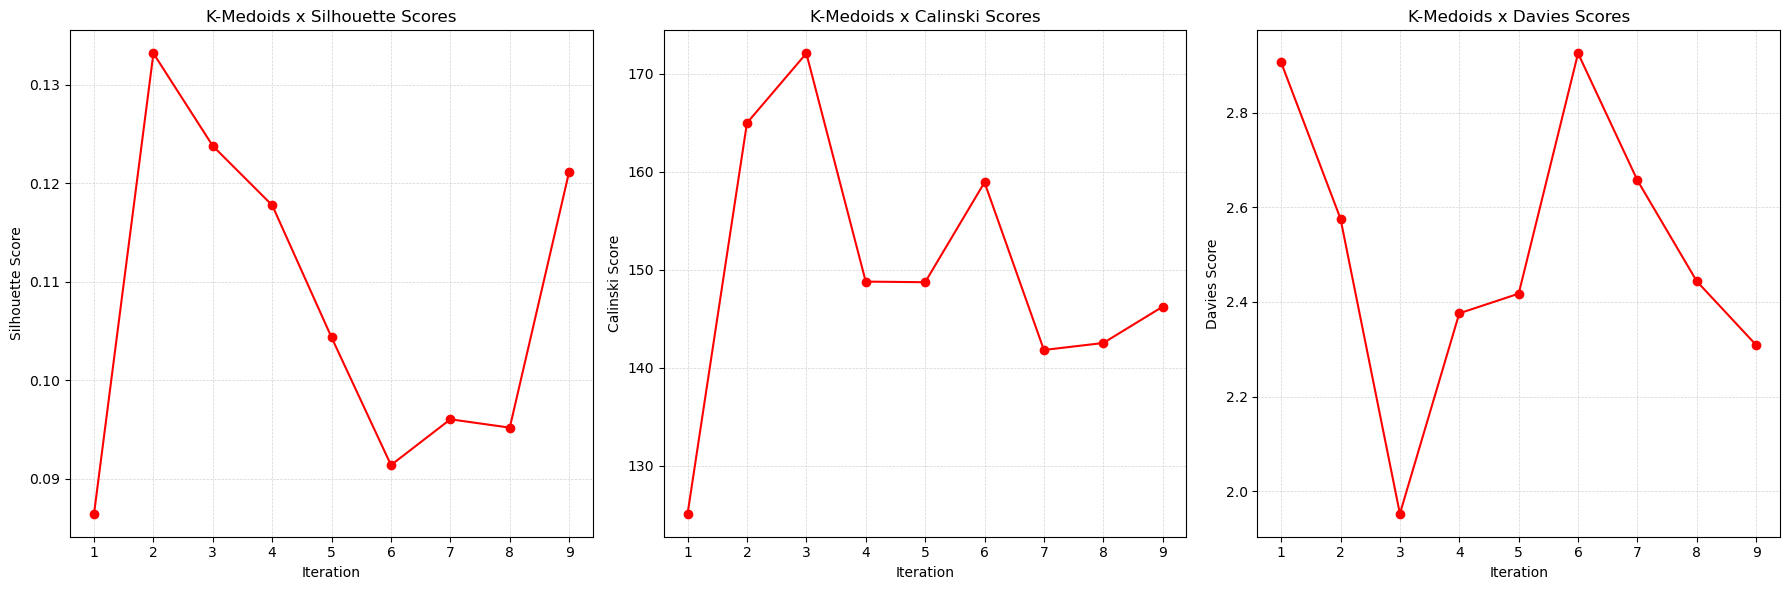

In [79]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.utils import resample
import matplotlib.pyplot as plt
import numpy as np

def run_kmedoids(X, initial_k, random_state=42):
    while initial_k > 1:
        kmedoids = KMedoids(n_clusters=initial_k, random_state=random_state)
        kmedoids.fit(X)
        if np.min(np.bincount(kmedoids.labels_)) > 0:
            return kmedoids
        initial_k -= 1
    return None  # All clustering attempts failed

num_iterations = 10
best_k = 6  # Initial best_k value
scores = {'silhouette': [], 'calinski': [], 'davies': []}

for i in range(num_iterations):
    X_boot = resample(X_train_pca, n_samples=int(len(X_train_pca) * 0.8))
    kmedoids = run_kmedoids(X_boot, best_k)
    
    if kmedoids:
        labels = kmedoids.predict(X_boot)
        if len(set(labels)) > 1:
            scores['silhouette'].append(silhouette_score(X_boot, labels))
            scores['calinski'].append(calinski_harabasz_score(X_boot, labels))
            scores['davies'].append(davies_bouldin_score(X_boot, labels))
        else:
            print(f'Iteration {i+1}: Only one cluster present.')
    else:
        print(f'Iteration {i+1}: Failed to find a valid clustering.')

# Finding optimal scores
optimal_silhouette = max(scores['silhouette']) if scores['silhouette'] else None
optimal_calinski = max(scores['calinski']) if scores['calinski'] else None
optimal_davies = min(scores['davies']) if scores['davies'] else None

print(f"Optimal Silhouette Score: {optimal_silhouette}")
print(f"Optimal Calinski-Harabasz Index: {optimal_calinski}")
print(f"Optimal Davies-Bouldin Index: {optimal_davies}")

# Plot results
plt.figure(figsize=(18, 6))
for idx, (key, values) in enumerate(scores.items(), 1):
    plt.subplot(1, 3, idx)
    plt.plot(range(1, len(values) + 1), values, marker='o', linestyle='-', color='red')
    plt.title(f'K-Medoids x {key.capitalize()} Scores')
    plt.xlabel('Iteration')
    plt.ylabel(f'{key.capitalize()} Score')
    plt.grid(True, linestyle='--', linewidth=0.5, color='lightgrey')

plt.tight_layout()
plt.show()


In [80]:
# from sklearn_extra.cluster import KMedoids
# from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
# import matplotlib.pyplot as plt

# # Assuming best_k has been defined based on your analysis
# # best_k = 6  # Replace with your actual best_k value
# kmedoids = KMedoids(n_clusters=best_k, random_state=42)
# kmedoids.fit(X_train_pca)

# # Predict the cluster labels for the PCA-transformed training data
# kmedoids_train_labels = kmedoids.predict(X_train_pca)

# # Silhouette Coefficient
# silhouette_avg = silhouette_score(X_train_pca, kmedoids_train_labels)
# print(f'Silhouette Coefficient: {silhouette_avg}')

# # Calinski-Harabasz Index
# calinski_harabasz = calinski_harabasz_score(X_train_pca, kmedoids_train_labels)
# print(f'Calinski-Harabasz Index: {calinski_harabasz}')

# # Davies-Bouldin Index
# davies_bouldin = davies_bouldin_score(X_train_pca, kmedoids_train_labels)
# print(f'Davies-Bouldin Index: {davies_bouldin}')

# # Visualizing the clusters in the context of the first two principal components
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=kmedoids_train_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k')
# plt.scatter(kmedoids.cluster_centers_[:, 0], kmedoids.cluster_centers_[:, 1], c='red', s=200, marker='x')  # Centroids
# plt.title('K-Medoids Clustering: Market Segmentation Data in Space of PC1 and PC2')
# plt.xlabel(pca1)  # Replace with pca1 variable or string label if needed
# plt.ylabel(pca2)  # Replace with pca2 variable or string label if needed
# plt.colorbar(label='Cluster Label')
# plt.show()


In [81]:
# from sklearn_extra.cluster import KMedoids

# # Assuming best_k has been defined based on your analysis
# kmedoids = KMedoids(n_clusters=best_k, random_state=42)
# kmedoids.fit(X_train_pca)

# # Predict the cluster labels for the PCA-transformed training data
# kmedoids_train_labels = kmedoids.predict(X_train_pca)


# # Optionally, predict the cluster labels for the PCA-transformed test data
# # kmedoids_test_labels = kmedoids.predict(X_test_pca)

# # Visualizing the clusters in the context of the first two principal components
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=kmedoids_train_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k')
# plt.scatter(kmedoids.cluster_centers_[:, 0], kmedoids.cluster_centers_[:, 1], c='red', s=200, marker='x')  # Centroids
# plt.title('K-Medoids Clustering: Market Segmentation Data in Space of PC1 and PC2') #Partition
# plt.xlabel(pca1) #'PCA 1')
# plt.ylabel(pca2) #'PCA 2')
# plt.colorbar(label='Cluster Label')
# plt.show()


**DBSCAN Clustering**

Optimal Silhouette Score: 0.4503709034893577
Optimal Calinski-Harabasz Index: 156.9519825145182
Optimal Davies-Bouldin Index: 0.7270679313177161


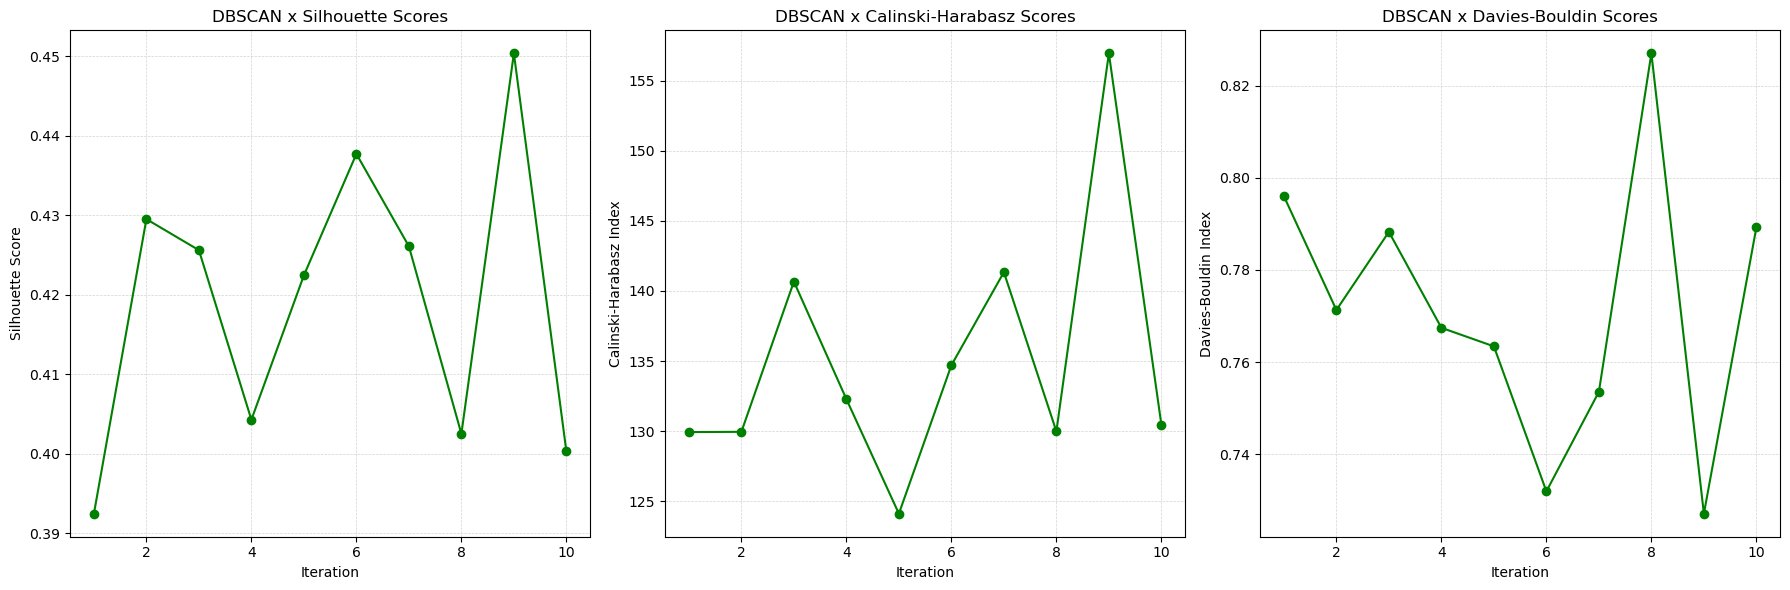

In [82]:

import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import matplotlib.pyplot as plt
from sklearn.utils import resample

# Assuming X_train_pca is your PCA-transformed data
num_iterations = 10  # Number of bootstrapping iterations
silhouette_scores = []
calinski_scores = []
davies_scores = []

for i in range(num_iterations):
    # Resample the data to create a bootstrap sample
    X_boot = resample(X_train_pca, n_samples=int(len(X_train_pca) * 0.8))
    
    # Initialize and fit DBSCAN
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    y_pred = dbscan.fit_predict(X_boot)

    # Filter out noise for metric calculation
    mask = y_pred != -1
    if np.unique(y_pred[mask]).size > 1:  # Ensure there's more than one cluster
        # Calculate and store each metric
        silhouette_avg = silhouette_score(X_boot[mask], y_pred[mask])
        silhouette_scores.append(silhouette_avg)
        
        calinski = calinski_harabasz_score(X_boot[mask], y_pred[mask])
        calinski_scores.append(calinski)
        
        davies = davies_bouldin_score(X_boot[mask], y_pred[mask])
        davies_scores.append(davies)
        
        # print(f'Iteration {i+1}: Silhouette Score = {silhouette_avg}, Calinski-Harabasz = {cal…

# Identify the optimal scores
optimal_silhouette = max(silhouette_scores) if silhouette_scores else None
optimal_calinski = max(calinski_scores) if calinski_scores else None
optimal_davies = min(davies_scores) if davies_scores else None

print(f"Optimal Silhouette Score: {optimal_silhouette}")
print(f"Optimal Calinski-Harabasz Index: {optimal_calinski}")
print(f"Optimal Davies-Bouldin Index: {optimal_davies}")

# Plotting all metrics as subplots
plt.figure(figsize=(18, 6))

# Silhouette Scores
plt.subplot(1, 3, 1)
plt.plot(range(1, len(silhouette_scores) + 1), silhouette_scores, marker='o', linestyle='-', color='g')
plt.title('DBSCAN x Silhouette Scores')
plt.xlabel('Iteration')
plt.ylabel('Silhouette Score')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

# Calinski-Harabasz Scores
plt.subplot(1, 3, 2)
plt.plot(range(1, len(calinski_scores) + 1), calinski_scores, marker='o', linestyle='-', color='g')
plt.title('DBSCAN x Calinski-Harabasz Scores')
plt.xlabel('Iteration')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

# Davies-Bouldin Scores
plt.subplot(1, 3, 3)
plt.plot(range(1, len(davies_scores) + 1), davies_scores, marker='o', linestyle='-', color='g')
plt.title('DBSCAN x Davies-Bouldin Scores')
plt.xlabel('Iteration')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


In [83]:
# from sklearn.cluster import DBSCAN

# # Initialize DBSCAN with estimated parameters for eps and min_samples
# # Note: These parameters are highly data-dependent and should be tuned accordingly
# dbscan = DBSCAN(eps=0.5, min_samples=5)
# dbscan_train_labels = dbscan.fit_predict(X_train_pca)

# # Visualizing the clusters
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=dbscan_train_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k')
# plt.title('DBSCAN (Density-Based) Clustering')
# plt.xlabel(pca1) #'PCA 1')
# plt.ylabel(pca2) #'PCA 2')
# plt.colorbar(label='Cluster Label')
# plt.show()


**Hierarchical Clustering - AGNES**

Optimal Silhouette Score: 0.12898060361644184
Optimal Calinski-Harabasz Index: 161.37714533735615
Optimal Davies-Bouldin Index: 1.9981975682876274


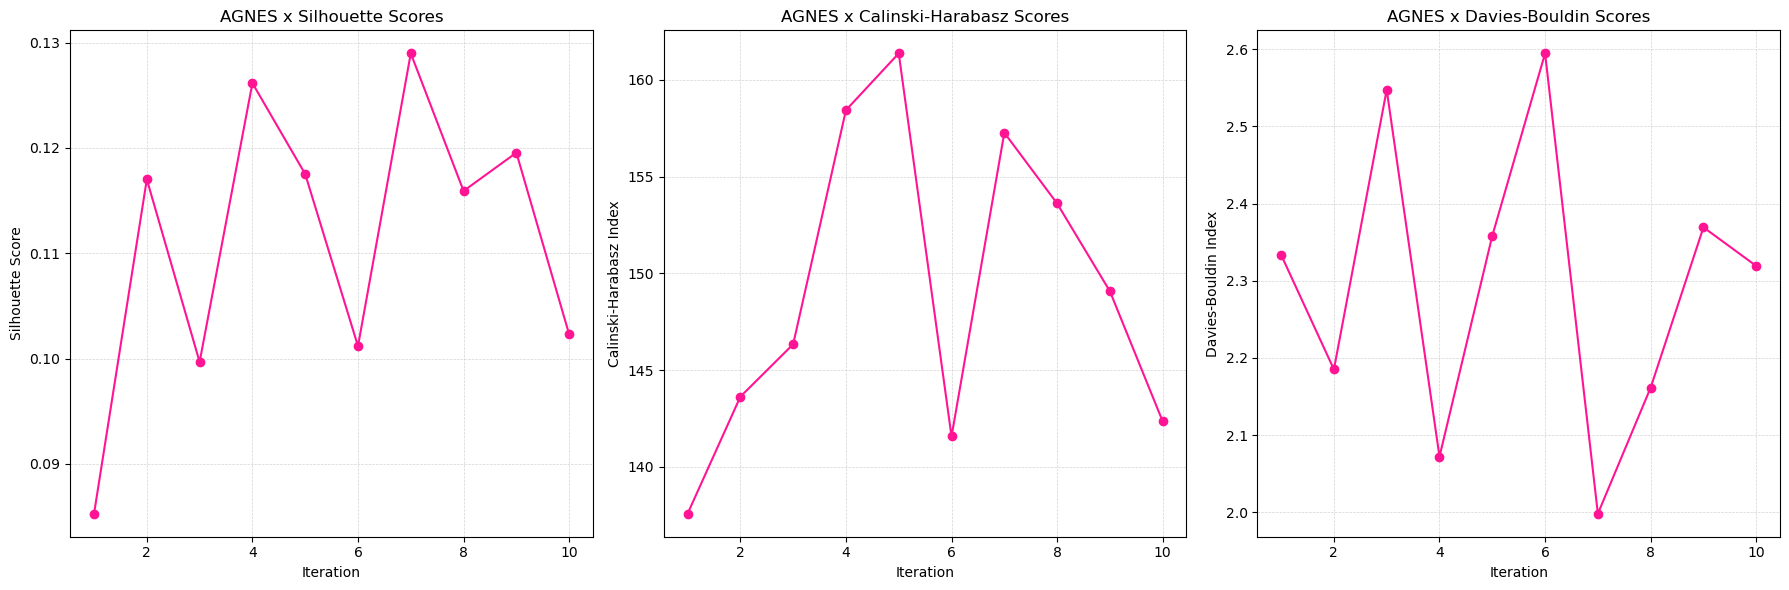

In [84]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import matplotlib.pyplot as plt
from sklearn.utils import resample

# Assuming X_train_pca is your PCA-transformed data
num_iterations = 10  # Number of bootstrap samples
best_k = 5  # Replace with actual determined value after dendrogram analysis
silhouette_scores = []
calinski_scores = []
davies_scores = []

for i in range(num_iterations):
    # Resample the data
    X_boot = resample(X_train_pca, n_samples=int(len(X_train_pca) * 0.8))

    # Perform Agglomerative Clustering
    agg_clustering = AgglomerativeClustering(n_clusters=best_k, linkage='complete')
    labels = agg_clustering.fit_predict(X_boot)

    # Only compute metrics if there are more than one cluster
    if len(set(labels)) > 1:
        # Silhouette Coefficient
        silhouette_avg = silhouette_score(X_boot, labels)
        silhouette_scores.append(silhouette_avg)
        
        # Calinski-Harabasz Index
        calinski_harabasz = calinski_harabasz_score(X_boot, labels)
        calinski_scores.append(calinski_harabasz)
        
        # Davies-Bouldin Index
        davies_bouldin = davies_bouldin_score(X_boot, labels)
        davies_scores.append(davies_bouldin)
        
        # print(f'Iteration {i+1}: Silhouette = {silhouette_avg}, Calinski-Harabasz = {calinski_harabasz}, Davies-Bouldin = {davies_bouldin}')
    else:
        print(f'Iteration {i+1}: Not enough clusters for metric calculation')

# Identify the optimal scores
optimal_silhouette = max(silhouette_scores) if silhouette_scores else None
optimal_calinski = max(calinski_scores) if calinski_scores else None
optimal_davies = min(davies_scores) if davies_scores else None

print(f"Optimal Silhouette Score: {optimal_silhouette}")
print(f"Optimal Calinski-Harabasz Index: {optimal_calinski}")
print(f"Optimal Davies-Bouldin Index: {optimal_davies}")

# Plotting all metrics as subplots
plt.figure(figsize=(18, 6))

# Silhouette Scores
plt.subplot(1, 3, 1)
plt.plot(range(1, len(silhouette_scores) + 1), silhouette_scores, marker='o', linestyle='-', color='deeppink')
plt.title('AGNES x Silhouette Scores')
plt.xlabel('Iteration')
plt.ylabel('Silhouette Score')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

# Calinski-Harabasz Scores
plt.subplot(1, 3, 2)
plt.plot(range(1, len(calinski_scores) + 1), calinski_scores, marker='o', linestyle='-', color='deeppink')
plt.title('AGNES x Calinski-Harabasz Scores')
plt.xlabel('Iteration')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

# Davies-Bouldin Scores
plt.subplot(1, 3, 3)
plt.plot(range(1, len(davies_scores) + 1), davies_scores, marker='o', linestyle='-', color='deeppink')
plt.title('AGNES x Davies-Bouldin Scores')
plt.xlabel('Iteration')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


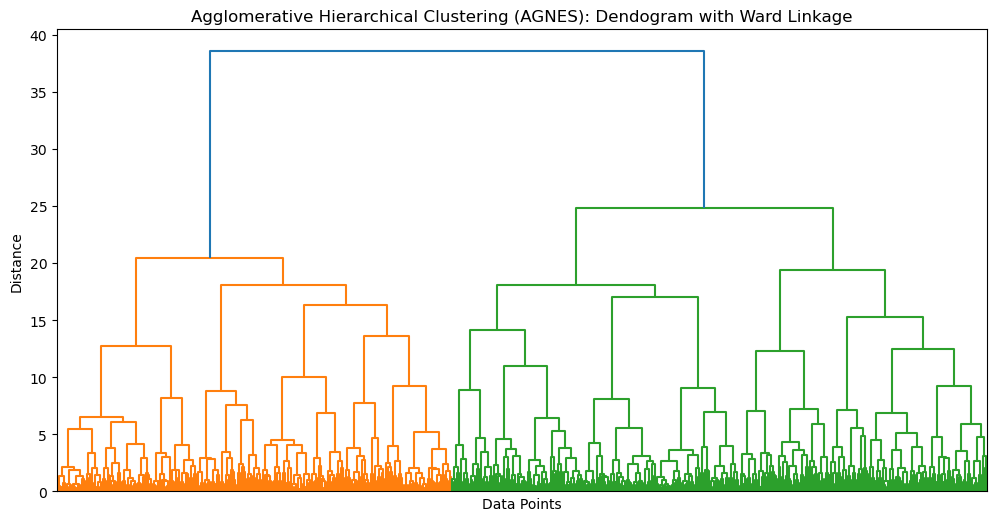

In [85]:


# Linkage matrix using Ward's method
Z = linkage(X_train_pca, 'ward') #

# Plotting the dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z, no_labels=True)  # no_labels is set to True for a cleaner plot
plt.title('Agglomerative Hierarchical Clustering (AGNES): Dendogram with Ward Linkage')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()





# # from scipy.cluster.hierarchy import dendrogram, linkage, fcluster


# # # Assume X_train is your dataset and it's already loaded as a DataFrame

# # # # Step 1: Perform Agglomerative Hierarchical Clustering
# # # # Using Ward's linkage method
# # # Z = linkage(X_train_pca, method='ward')

# # # # Step 2: Plotting the dendrogram
# # # plt.figure(figsize=(12, 8))
# # # dendrogram(Z)
# # # plt.title('Agglomerative Hierarchical Clustering (AGNES): Dendrogram with Complete Linkage')
# # # plt.xlabel('Data Points')
# # # plt.ylabel('Distance')
# # # plt.show()

# # # Step 3: Generate cluster labels using a chosen distance threshold
# # threshold = 2  # Adjust this threshold by inspecting the dendrogram
# # cluster_labels = fcluster(Z, threshold, criterion='distance')

# # # Step 4: Map Labels to Original Data
# # X_train['Cluster_Label'] = cluster_labels

# # # Step 5: Retrieve the color mapping from dendrogram
# # dendro = dendrogram(Z)
# # plt.close()  # Close the dendrogram plot as we just need the color information

# # # The 'ivl' key holds the index of the leaves in the same order as they are plotted in the dendrogram
# # ivl_order = [int(i) for i in dendro['ivl']]
# # # Create a mapping of index to color
# # index_to_color = dict(zip(ivl_order, dendro['color_list']))

# # # df_X_train_pca = pd.DataFrame(X_train_pca)

# # # Assign colors to the original dataset based on cluster labels
# # X_train['Color'] = df_X_train_pca.index.map(index_to_color)

# # # Step 6: Plotting the original data with cluster colors
# # # Assume 'feature1' and 'feature2' are your main features of interest for plotting
# # sns.scatterplot(x=df_X_train_pca[0], y=df_X_train_pca[1], data=df_X_train_pca, hue='Color', palette='Spectral', legend=None)
# # plt.title('Original Data Colored by Cluster Label from Dendrogram')
# # plt.show()
 




# # # Perform Agglomerative Hierarchical Clustering using Ward's linkage method
# # Z = linkage(X_train_pca, method='ward')

# # # Generate cluster labels using a chosen distance threshold
# # threshold = 2  # This should be set based on dendrogram inspection
# # df_X_train_pca['Cluster_Label'] = fcluster(Z, threshold, criterion='distance')

# # # Create the dendrogram to get the color mapping
# # dendro = dendrogram(Z)
# # plt.title('Agglomerative Hierarchical Clustering (AGNES)')
# # plt.xlabel('Data Points')
# # plt.ylabel('Distance')
# # plt.show()

# # # The color list is the fourth output of the dendrogram function
# # dendro_color_list = dendro['color_list'] 
# # # Note: This color list is not directly correlated with the original data points, 
# # # it's related to the linkage matrix.

# # # Plotting the PCA-transformed data with clusters
# # plt.figure(figsize=(10, 8))
# # sns.scatterplot(x='PCA1', y='AcceptedCmp4', data=X_train_pca, hue='Cluster_Label', palette='Spectral')
# # plt.title('PCA Data Colored by Cluster Label')
# # plt.xlabel(pca1)
# # plt.ylabel(pca2)
# # plt.colorbar()
# # plt.show()

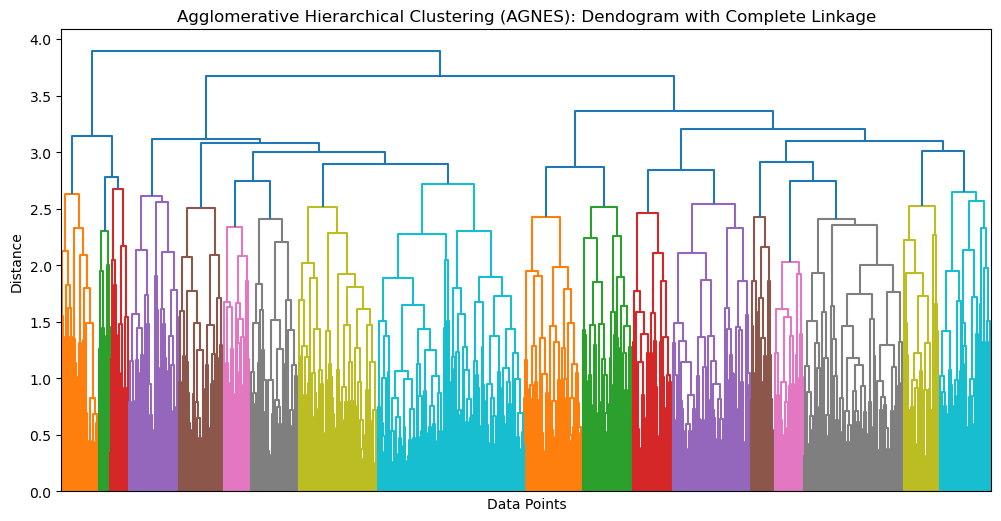

In [86]:
Z = linkage(X_train_pca, 'complete') #

# Plotting the dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z, no_labels=True)  # no_labels is set to True for a cleaner plot
plt.title('Agglomerative Hierarchical Clustering (AGNES): Dendogram with Complete Linkage')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()


**Hierarchical Clustering - DIANA**

In [87]:
# def diana(data, k):
#     clusters = [data]  # Start with all points in one cluster
#     while len(clusters) < k:
#         # Choose the most heterogeneous cluster
#         cluster_to_split = max(clusters, key=lambda x: calculate_heterogeneity(x))
        
#         # Find splinter group by identifying point(s) furthest from centroid
#         centroid = np.mean(cluster_to_split, axis=0)
#         distances = np.linalg.norm(cluster_to_split - centroid, axis=1)
#         splinter_group = cluster_to_split[distances > np.mean(distances)]
        
#         # Split the cluster
#         new_cluster = [point for point in cluster_to_split if point not in splinter_group]
#         clusters.remove(cluster_to_split)
#         clusters.append(new_cluster)
#         clusters.append(splinter_group)
        
#     return clusters

# # Helper function to calculate heterogeneity of a cluster
# def calculate_heterogeneity(cluster):
#     centroid = np.mean(cluster, axis=0)
#     distances = np.linalg.norm(cluster - centroid, axis=1)
#     return np.mean(distances)


In [88]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.cluster.hierarchy import dendrogram

# def recursive_divisive_clustering(data, depth=0, max_depth=2, cluster_id=0, linkage_matrix=[], current_index=0):
#     n_samples = data.shape[0]

#     if depth >= max_depth or n_samples <= 1:
#         return current_index

#     # Find the dimension with the greatest variance and split along its median
#     variances = np.var(data, axis=0)
#     split_dim = np.argmax(variances)
#     median_val = np.median(data[:, split_dim])

#     left_indices = data[:, split_dim] <= median_val
#     right_indices = ~left_indices

#     left_data = data[left_indices]
#     right_data = data[right_indices]

#     # Assume each division increases the distance in dendrogram
#     distance = depth * 10

#     # Update linkage matrix
#     left_size = left_data.shape[0]
#     right_size = right_data.shape[0]
#     linkage_matrix.append([current_index, current_index + 1, distance, left_size])
#     linkage_matrix.append([current_index + 1, current_index + 2, distance, right_size])

#     # Recursive call for each part
#     new_index = current_index + 2
#     last_index_left = recursive_divisive_clustering(left_data, depth + 1, max_depth, cluster_id + 1, linkage_matrix, new_index)
#     new_index = last_index_left + 1
#     last_index_right = recursive_divisive_clustering(right_data, depth + 1, max_depth, cluster_id + 2, linkage_matrix, new_index)

#     return last_index_right

# # Example data: Using a simple dataset for illustration
# data = np.random.rand(100, 2)  # 100 points in 2D

# linkage_matrix = []
# recursive_divisive_clustering(data, max_depth=3, linkage_matrix=linkage_matrix)

# # Convert linkage matrix to numpy array
# linkage_matrix = np.array(linkage_matrix)

# # Plotting the dendrogram
# plt.figure(figsize=(10, 8))
# dendrogram(linkage_matrix)
# plt.title('DIANA-like Dendrogram')
# plt.xlabel('Index of Cluster')
# plt.ylabel('Distance')
# plt.show()


In [89]:
# import numpy as np
# import matplotlib.pyplot as plt

# def simple_divisive_clustering(data, max_depth=2, depth=0):
#     # Base case: if max depth is reached, return data as a single cluster
#     if depth >= max_depth or len(data) < 2:
#         return [data]

#     # Determine the dimension with the greatest variance to split on for simplicity
#     variances = np.var(data, axis=0)
#     split_dim = np.argmax(variances)

#     # Split the data into two clusters based on the median of the chosen dimension
#     median_value = np.median(data[:, split_dim])
#     left_cluster = data[data[:, split_dim] <= median_value]
#     right_cluster = data[data[:, split_dim] > median_value]

#     # Recursively apply the same divisive process to the resulting clusters
#     left_clusters = simple_divisive_clustering(left_cluster, max_depth, depth + 1)
#     right_clusters = simple_divisive_clustering(right_cluster, max_depth, depth + 1)

#     return left_clusters + right_clusters

# # Example usage on your PCA-transformed data, assuming X_train_pca is available
# clusters = simple_divisive_clustering(X_train_pca, max_depth=3)

# # Plotting function for the clusters
# def plot_clusters(clusters):
#     plt.figure(figsize=(10, 8))
#     colors = plt.cm.viridis(np.linspace(0, 1, len(clusters)))
#     for cluster, color in zip(clusters, colors):
#         plt.scatter(cluster[:, 0], cluster[:, 1], s=30, alpha=0.5, color=color)

#     plt.title('Divisive Hierarchical Clustering (DIANA)')
#     plt.xlabel(pca1) #'PCA 1')
#     plt.ylabel(pca2) #'PCA 2')
#     plt.show()

# plot_clusters(clusters)


**Grid-Based Clustering: Simple Grid-Based Clustering**

...sophisticated algorithms like CLIQUE, STING, or WaveCluster

Optimal Silhouette Score: -0.03373328948909984
Optimal Calinski-Harabasz Index: 25.017507729181066
Optimal Davies-Bouldin Index: 3.086236641751598


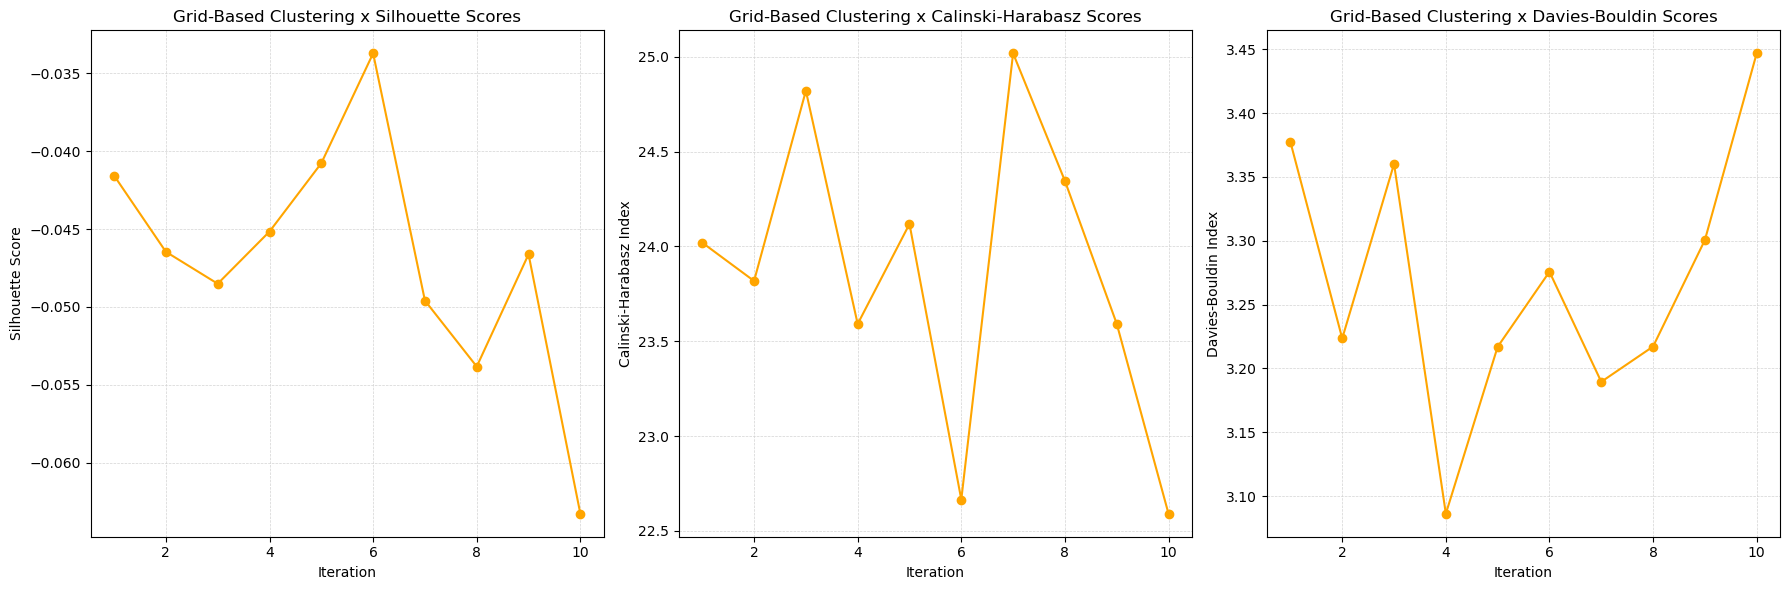

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.utils import resample

def simple_grid_clustering(data, grid_size):
    # Determine the extent of the grid
    min_x, max_x = np.min(data[:, 0]), np.max(data[:, 0])
    min_y, max_y = np.min(data[:, 1]), np.max(data[:, 1])

    # Create a grid of specified grid size
    x_bins = np.linspace(min_x, max_x, num=grid_size)
    y_bins = np.linspace(min_y, max_y, num=grid_size)

    # Digitize puts each data point into a bin
    x_bin_indices = np.digitize(data[:, 0], bins=x_bins)
    y_bin_indices = np.digitize(data[:, 1], bins=y_bins)

    # Combine x and y bin indices to form grid cell labels
    grid_labels = (x_bin_indices - 1) * grid_size + (y_bin_indices - 1)

    return grid_labels

num_iterations = 10  # Number of bootstrapping iterations
grid_size = 10  # Grid size for the clustering
silhouette_scores = []
calinski_scores = []
davies_scores = []

for i in range(num_iterations):
    # Resample the data
    X_boot = resample(X_train_pca, n_samples=int(len(X_train_pca) * 0.8))

    # Apply the simple grid clustering on PCA-transformed data
    grid_labels = simple_grid_clustering(X_boot, grid_size)

    # Calculate metrics
    silhouette_avg = silhouette_score(X_boot, grid_labels)
    calinski_harabasz = calinski_harabasz_score(X_boot, grid_labels)
    davies_bouldin = davies_bouldin_score(X_boot, grid_labels)

    # Append metrics
    silhouette_scores.append(silhouette_avg)
    calinski_scores.append(calinski_harabasz)
    davies_scores.append(davies_bouldin)

    # print(f'Iteration {i+1}: Silhouette = {silhouette_avg}, Calinski-Harabasz = {calinski_harabasz}, Davies-Bouldin = {davies_bouldin}')

# Identify the optimal scores
optimal_silhouette = max(silhouette_scores)
optimal_calinski = max(calinski_scores)
optimal_davies = min(davies_scores)

print(f"Optimal Silhouette Score: {optimal_silhouette}")
print(f"Optimal Calinski-Harabasz Index: {optimal_calinski}")
print(f"Optimal Davies-Bouldin Index: {optimal_davies}")

# Plotting all metrics as subplots
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.plot(range(1, len(silhouette_scores) + 1), silhouette_scores, marker='o', linestyle='-', color='orange')
plt.title('Grid-Based Clustering x Silhouette Scores')
plt.xlabel('Iteration')
plt.ylabel('Silhouette Score')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

plt.subplot(1, 3, 2)
plt.plot(range(1, len(calinski_scores) + 1), calinski_scores, marker='o', linestyle='-', color='orange')
plt.title('Grid-Based Clustering x Calinski-Harabasz Scores')
plt.xlabel('Iteration')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

plt.subplot(1, 3, 3)
plt.plot(range(1, len(davies_scores) + 1), davies_scores, marker='o', linestyle='-', color='orange')
plt.title('Grid-Based Clustering x Davies-Bouldin Scores')
plt.xlabel('Iteration')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True, color='lightgrey', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


In [91]:
# import numpy as np
# import matplotlib.pyplot as plt

# def simple_grid_clustering(data, grid_size):
#     # Determine the extent of the grid
#     min_x, max_x = np.min(data[:, 0]), np.max(data[:, 0])
#     min_y, max_y = np.min(data[:, 1]), np.max(data[:, 1])

#     # Create a grid of specified grid size
#     x_bins = np.linspace(min_x, max_x, num=grid_size)
#     y_bins = np.linspace(min_y, max_y, num=grid_size)

#     # Digitize puts each data point into a bin
#     x_bin_indices = np.digitize(data[:, 0], bins=x_bins)
#     y_bin_indices = np.digitize(data[:, 1], bins=y_bins)

#     # Combine x and y bin indices to form grid cell labels
#     grid_labels = (x_bin_indices - 1) * grid_size + (y_bin_indices - 1)

#     return grid_labels

# # Apply the simple grid clustering on PCA-transformed data
# grid_labels = simple_grid_clustering(X_train_pca, grid_size=10)

# # Plotting
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=grid_labels, cmap='viridis', marker='o', alpha=0.5)
# plt.colorbar(label='Grid Cell Label')
# plt.title('Grid-Based Clustering')
# plt.xlabel(pca1) #'PCA 1')
# plt.ylabel(pca2) #'PCA 2')
# plt.show()


**Model-Baased: EM Clustering**

Optimal Silhouette Score: 0.1566453339780587
Optimal Calinski-Harabasz Index: 182.48933622490742
Optimal Davies-Bouldin Index: 1.985986462141313


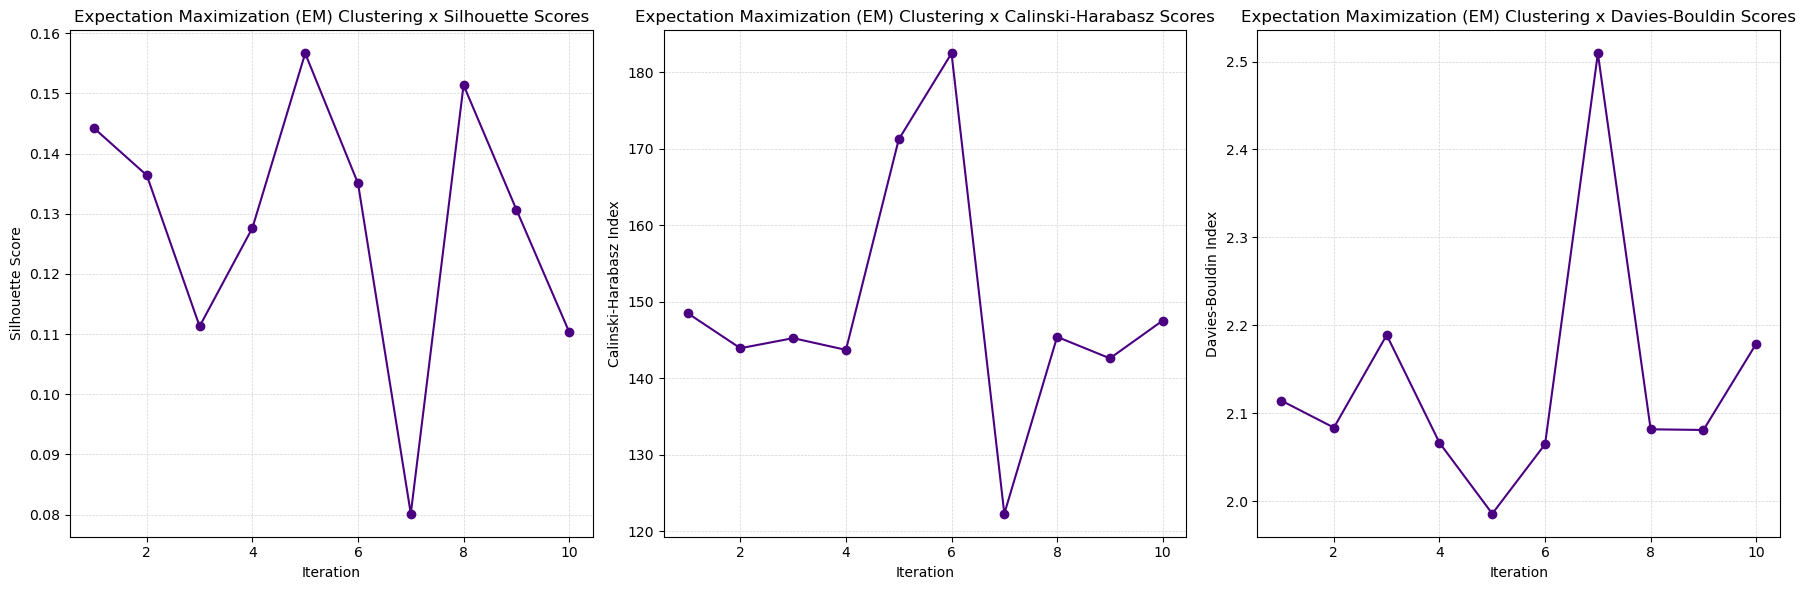

In [92]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.utils import resample
import matplotlib.pyplot as plt
import numpy as np

# Assuming X_train_pca is your PCA-transformed data and best_k is set
# best_k = 5  # Adjust this value based on your analysis
num_iterations = 10  # Number of bootstrap iterations
silhouette_scores = []
calinski_scores = []
davies_scores = []

for i in range(num_iterations):
    # Resample the data
    X_boot = resample(X_train_pca, n_samples=int(len(X_train_pca) * 0.8))

    # Initialize the Gaussian Mixture Model
    gmm = GaussianMixture(n_components=best_k, random_state=42)
    
    # Fit the model on the PCA-transformed training data
    gmm.fit(X_boot)
    
    # Predict the cluster labels
    labels = gmm.predict(X_boot)

    # Only compute metrics if there are more than one cluster
    if len(set(labels)) > 1:
        # Silhouette Coefficient
        silhouette_avg = silhouette_score(X_boot, labels)
        silhouette_scores.append(silhouette_avg)
        
        # Calinski-Harabasz Index
        calinski_harabasz = calinski_harabasz_score(X_boot, labels)
        calinski_scores.append(calinski_harabasz)
        
        # Davies-Bouldin Index
        davies_bouldin = davies_bouldin_score(X_boot, labels)
        davies_scores.append(davies_bouldin)
        
        # print(f'Iteration {i+1}: Silhouette = {silhouette_avg}, Calinski-Harabasz = {calinski_harabasz}, Davies-Bouldin = {davies_bouldin}')
    else:
        print(f'Iteration {i+1}: Not enough clusters for metric calculation')

# Identify the optimal scores
optimal_silhouette = max(silhouette_scores) if silhouette_scores else None
optimal_calinski = max(calinski_scores) if calinski_scores else None
optimal_davies = min(davies_scores) if davies_scores else None

print(f"Optimal Silhouette Score: {optimal_silhouette}")
print(f"Optimal Calinski-Harabasz Index: {optimal_calinski}")
print(f"Optimal Davies-Bouldin Index: {optimal_davies}")

# Plotting all metrics as subplots
plt.figure(figsize=(18, 6))

# Silhouette Scores
plt.subplot(1, 3, 1)
plt.plot(range(1, len(silhouette_scores) + 1), silhouette_scores, marker='o', linestyle='-', color='indigo')
plt.title('Expectation Maximization (EM) Clustering x Silhouette Scores')
plt.xlabel('Iteration')
plt.ylabel('Silhouette Score')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Calinski-Harabasz Scores
plt.subplot(1, 3, 2)
plt.plot(range(1, len(calinski_scores) + 1), calinski_scores, marker='o', linestyle='-', color='indigo')
plt.title('Expectation Maximization (EM) Clustering x Calinski-Harabasz Scores')
plt.xlabel('Iteration')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Davies-Bouldin Scores
plt.subplot(1, 3, 3)
plt.plot(range(1, len(davies_scores) + 1), davies_scores, marker='o', linestyle='-', color='indigo')
plt.title('Expectation Maximization (EM) Clustering x Davies-Bouldin Scores')
plt.xlabel('Iteration')
plt.ylabel('Davies-Bouldin Index')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


In [93]:
# from sklearn.mixture import GaussianMixture
# import matplotlib.pyplot as plt
# import numpy as np

# # Define the number of clusters/components
# n_clusters = best_k  # Assuming you have some way of defining this, or you could experiment with different values

# # Initialize the Gaussian Mixture Model
# gmm = GaussianMixture(n_components=n_clusters, random_state=42)

# # Fit the model on the PCA-transformed training data
# gmm.fit(X_train_pca)

# # Predict the cluster labels
# labels = gmm.predict(X_train_pca)

# # Optionally, predict the probabilities for each data point (soft clustering)
# probs = gmm.predict_proba(X_train_pca)

# # Plotting the clusters
# plt.figure(figsize=(10, 8))
# plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=labels, cmap='viridis', marker='o', alpha=0.5, edgecolor='k')
# plt.title('Model-Based -- Expectation Maximization (EM) Clustering')  #(Model-Based) with Gaussian Mixture Models
# plt.xlabel(pca1) #'PCA 1')
# plt.ylabel(pca2) #'PCA 2')
# plt.colorbar(label='Cluster Label')
# plt.show()


In [94]:
# # Initialize a list to store silhouette scores and the corresponding number of clusters
# valid_scores = []

# # Try different numbers of clusters
# for n_clusters in range(2, 7):  # Example: Testing clusters from 2 to 6
#     # Initialize KMedoids with a more robust starting condition (e.g., 'k-medoids++' if available)
#     # As of my last update, 'k-medoids++' isn't a standard option, so we use the default which is equivalent to 'random'
#     kmedoids = KMedoids(n_clusters=n_clusters, random_state=42, init='random')
    
#     # Fit the model
#     kmedoids.fit(df_pca)
    
#     # Check if we have any empty clusters
#     unique_labels = np.unique(kmedoids.labels_)
#     if len(unique_labels) == n_clusters:
#         # Calculate silhouette score only if all clusters have points
#         score = silhouette_score(df_pca, kmedoids.labels_)
#         valid_scores.append((n_clusters, score))
#     else:
#         print(f"Skipping {n_clusters} clusters due to empty cluster formation.")

# # Print the silhouette scores for each valid number of clusters
# for n_clusters, score in valid_scores:
#     print(f"Valid clustering: Number of clusters: {n_clusters}, Silhouette Score: {score}")

In [95]:
# # Generate the linkage matrix using Ward's method
# Z = linkage(df_pca, 'single')

# # Plot the dendrogram
# plt.figure(figsize=(10, 7))
# plt.title('Hierarchical Clustering Dendrogram with Single Linkage')
# plt.xlabel('Sample index')
# plt.ylabel('Distance')
# dendrogram(
#     Z,
#     leaf_rotation=90.,  # rotates the x axis labels
#     leaf_font_size=8.,  # font size for the x axis labels
# )
# plt.show()

In [96]:
# # Generate the linkage matrix using Ward's method
# Z = linkage(df_pca, 'complete')

# # Plot the dendrogram
# plt.figure(figsize=(10, 7))
# plt.title('Hierarchical Clustering Dendrogram with Complete Linkage')
# plt.xlabel('Sample index')
# plt.ylabel('Distance')
# dendrogram(
#     Z,
#     leaf_rotation=90.,  # rotates the x axis labels
#     leaf_font_size=8.,  # font size for the x axis labels
# )
# plt.show()

In [97]:
# # Generate the linkage matrix using Ward's method
# Z = linkage(df_pca, 'average')

# # Plot the dendrogram
# plt.figure(figsize=(10, 7))
# plt.title('Hierarchical Clustering Dendrogram with Average Linkage')
# plt.xlabel('Sample index')
# plt.ylabel('Distance')
# dendrogram(
#     Z,
#     leaf_rotation=90.,  # rotates the x axis labels
#     leaf_font_size=8.,  # font size for the x axis labels
# )
# plt.show()

In [98]:
# # Generate the linkage matrix using Ward's method
# Z = linkage(df_pca, 'ward')

# # Plot the dendrogram
# plt.figure(figsize=(10, 7))
# plt.title('Hierarchical Clustering Dendrogram')
# plt.xlabel('Sample index')
# plt.ylabel('Distance')
# dendrogram(
#     Z,
#     leaf_rotation=90.,  # rotates the x axis labels
#     leaf_font_size=8.,  # font size for the x axis labels
# )
# plt.show()

### Evaluate Models

KMeans and DBSCAN best from the train

KMeans Test Metrics:
Silhouette Score: 0.18233305645329528
Calinski-Harabasz Index: 57.0161448583411
Davies-Bouldin Index: 1.7554143999668985
AGNES Test Metrics:
Silhouette Score: 0.18179623606025794
Calinski-Harabasz Index: 59.08154743972603
Davies-Bouldin Index: 1.8102216132263635


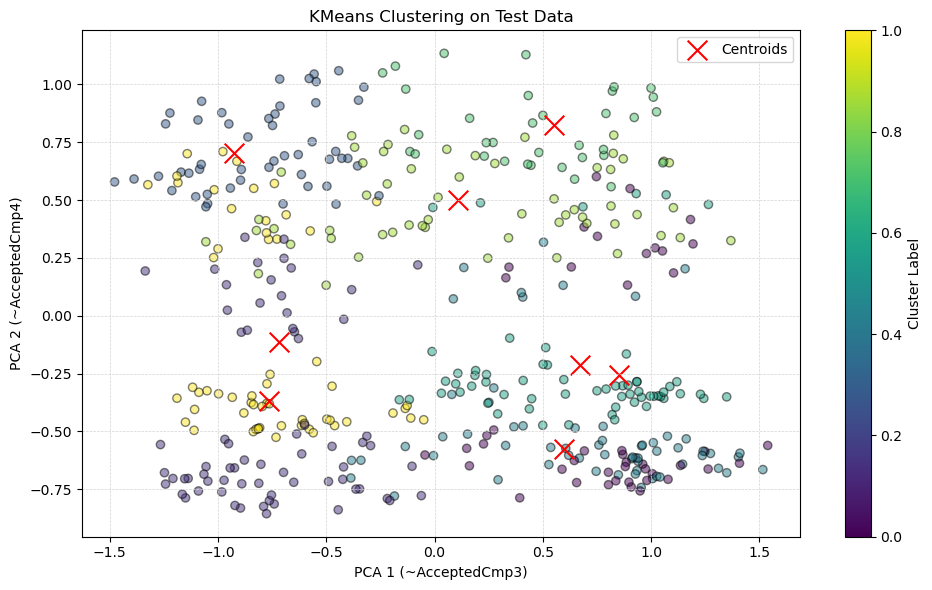

In [99]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Assuming 'X_test_pca' is your PCA-transformed test data and 'kmeans' is your trained KMeans model
# KMeans: Apply the already trained model to the test data
kmeans_test_labels = kmeans.predict(X_test_pca)

# AGNES Clustering
agnes = AgglomerativeClustering(n_clusters=best_k, linkage='ward')  # Adjust parameters as needed
agnes_test_labels = agnes.fit_predict(X_test_pca)

# Evaluate KMeans clustering
if len(set(kmeans_test_labels)) > 1:  # Ensure there's more than one cluster
    silhouette_kmeans = silhouette_score(X_test_pca, kmeans_test_labels)
    calinski_kmeans = calinski_harabasz_score(X_test_pca, kmeans_test_labels)
    davies_kmeans = davies_bouldin_score(X_test_pca, kmeans_test_labels)
    print("KMeans Test Metrics:")
    print(f"Silhouette Score: {silhouette_kmeans}")
    print(f"Calinski-Harabasz Index: {calinski_kmeans}")
    print(f"Davies-Bouldin Index: {davies_kmeans}")

# Evaluate AGNES clustering
if len(set(agnes_test_labels)) > 1:
    silhouette_agnes = silhouette_score(X_test_pca, agnes_test_labels)
    calinski_agnes = calinski_harabasz_score(X_test_pca, agnes_test_labels)
    davies_agnes = davies_bouldin_score(X_test_pca, agnes_test_labels)
    print("AGNES Test Metrics:")
    print(f"Silhouette Score: {silhouette_agnes}")
    print(f"Calinski-Harabasz Index: {calinski_agnes}")
    print(f"Davies-Bouldin Index: {davies_agnes}")

# Plotting KMeans Clusters and centroids
plt.figure(figsize=(10, 6))

# plt.subplot(1, 2, 1)
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=kmeans_test_labels, cmap='viridis', marker='o', alpha=0.5, edgecolor='k')
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='x', label='Centroids')
plt.title('KMeans Clustering on Test Data')
plt.xlabel(pca1)
plt.ylabel(pca2)
plt.colorbar(label='Cluster Label')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)
plt.legend()

# # Plotting AGNES Clusters
# plt.subplot(1, 2, 2)
# plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=agnes_test_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k')
# plt.title('AGNES Clustering on Test Data')
# plt.xlabel(pca1)
# plt.ylabel(pca2)
# plt.colorbar(label='Cluster Label')
# plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()


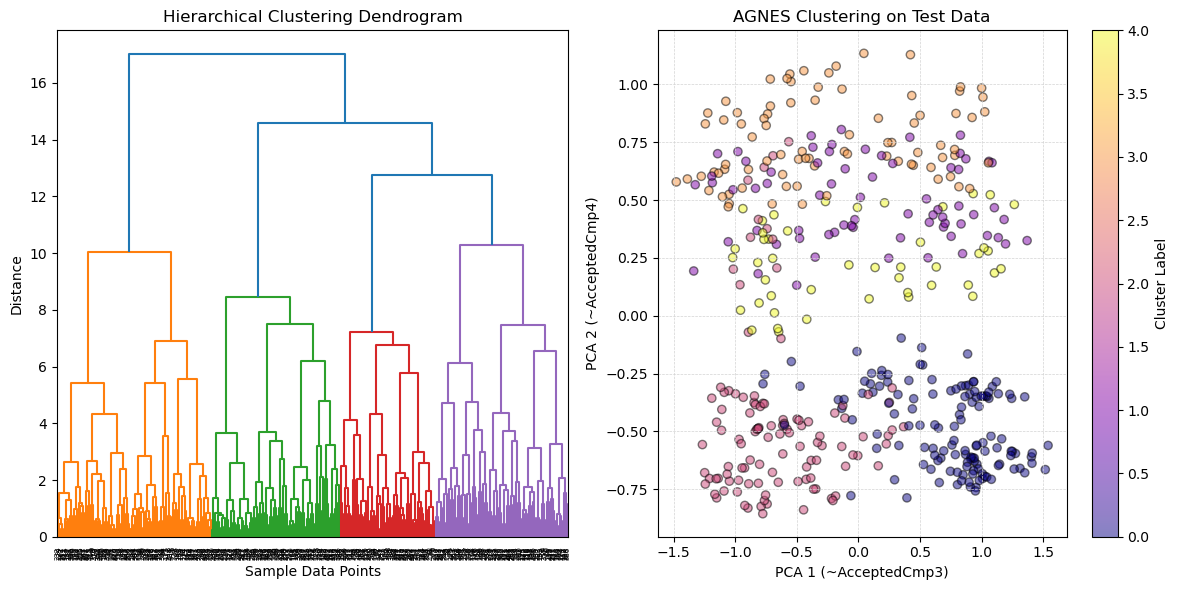

In [100]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering 

# Assuming 'X_test_pca' is your PCA-transformed test data
# Generate the linkage matrix
Z = linkage(X_test_pca, method='ward')

# Plotting the dendrogram
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Data Points')
plt.ylabel('Distance')
# plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

# Apply AGNES with a predetermined number of clusters
agnes = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
agnes_labels = agnes.fit_predict(X_test_pca)

# Plotting AGNES Clusters
plt.subplot(1, 2, 2)
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=agnes_labels, cmap='plasma', marker='o', alpha=0.5, edgecolor='k')
plt.title('AGNES Clustering on Test Data')
plt.xlabel(pca1)
plt.ylabel(pca2)
plt.colorbar(label='Cluster Label')
plt.grid(True, color='lightgrey',linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()
